# Task duration data analysis

**How to read this notebook.** Sections 1–4 explain the goal, check the data, and split it by time. Sections 5–12 explore the training data. Sections 13–15 explain what to verify before training and summarize the findings. Run the code cells from top to bottom.

## 1. Understand the prediction goal

Predict how many calendar days a web development task takes from work start to resolution. Each prediction is for one task. This is a **regression** problem because the answer is a number. The planned models are Random Forest Regressor, Gradient Boosting Regressor, and XGBoost Regressor. Check performance separately before using the model on teams or work outside this dataset.

| Field | Before work starts | When work begins |
|---|---|---|
| Title, description, task type, priority | Use the values recorded when the estimate is requested | Use the values recorded when the estimate is requested |
| Assignee history | Use verified tasks finished before the request | Use verified tasks finished before work starts |
| Actual start date | Unavailable | Use it if the recorded date is reliable |
| Completion duration | The outcome the model learns to predict | The outcome the model learns to predict |

The demo allows estimates before or at the start of work. The main analysis assumes the request happens when work begins. The split comparison also uses issue creation as an example of an earlier request. In both cases the model predicts days from work start to resolution.

**Before training.** Verify the start dates and assignee IDs. The project documents generated IDs in local copies and gaps in the original start-date records. Agree on how to count pauses, reopened tasks, and weekends. [Project README](../README.md), [estimate form](../src/App.jsx).

The notebook follows the reference guide's approach to checking data, viewing distributions, and investigating unusual values. [Gouranga Jha's EDA guide](https://medium.com/@post.gourang/a-holistic-guide-to-exploratory-data-analysis-eda-for-machine-learning-and-deep-learning-bc4f18f0143b).

## 2. Load and preview the data

Check which file contains the completion duration and inspect its columns. Read the CSV as text first so blanks and dates can be checked before converting them to numbers and timestamps. Run the notebook from the repository root or the `machine-learning` folder.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

try:
    import seaborn as sns
except ImportError:
    sns = None

if sns is not None:
    sns.set_theme(style="whitegrid")

target = "actual_completion_duration_days"
start_col = "actual_start_date"
resolved_col = "Resolved"
assignee_average = "assignee_average_completion_days"
group_cols = ["task_type", "Priority"]
priority_order = ["Highest", "High", "Normal", "Low", "Lowest"]  # Cleaner ranking
numeric_cols = [target, assignee_average, "priority_value", "prior_completed_tasks_used"]
date_cols = ["Created", start_col, resolved_col]
expected_roles = {
    "title": "Text input", "Description": "Text input",
    "task_type": "Categorical input", "Priority": "Categorical input",
    assignee_average: "Historical numeric input", start_col: "Conditional input",
    target: "Target",
}
audit_columns = ["issue_key", "assignee_id", "average_source", "Resolution"]
cwd = Path.cwd()
ml_dir = cwd if cwd.name == "machine-learning" else cwd / "machine-learning"
csv_path = ml_dir / "dataset.csv"
if not csv_path.is_file():
    raise FileNotFoundError("Open the repository root or machine-learning folder and provide machine-learning/dataset.csv.")

raw = pd.read_csv(csv_path, dtype="string", keep_default_na=False, encoding="utf-8-sig")
available_columns = set(raw.columns)
expected_columns = [*expected_roles, *numeric_cols, *date_cols, *audit_columns]
strings = raw.reindex(columns=list(dict.fromkeys([*raw.columns, *expected_columns]))).astype("string")
trimmed = strings.apply(lambda series: series.str.strip())
placeholders = trimmed.apply(lambda series: series.str.casefold().isin({"n/a", "na", "null", "none", "nan", "-", "unknown", "<na>"}))
df = trimmed.mask(trimmed.eq("") | placeholders)
for field in numeric_cols:
    df[field] = pd.to_numeric(df[field], errors="coerce").astype(float)
for field in date_cols:
    df[field] = pd.to_datetime(df[field], format="ISO8601", utc=True, errors="coerce")

print(f"Loaded machine-learning/{csv_path.name} with {len(raw):,} rows and {raw.shape[1]} columns.")
print(f"CSV size {csv_path.stat().st_size / 1024 ** 2:.2f} MiB. String DataFrame uses "
      f"{raw.memory_usage(deep=True).sum() / 1024 ** 2:.2f} MiB.")
print("Visualization backend:", "Seaborn and Matplotlib" if sns is not None else "Matplotlib")
with pd.option_context("display.max_colwidth", 58):
    print("First five rows")
    display(raw.head())
    print("Last five rows")
    display(raw.tail())

schema = pd.DataFrame({
    "CSV dtype": raw.dtypes.astype(str),
    "Analysis dtype": df.dtypes.astype(str),
    "Memory (KiB)": raw.memory_usage(index=False, deep=True).div(1024).round(1),
})
schema["Expected role"] = [expected_roles.get(field, "Metadata or derived field") for field in schema.index]
schema["Present in CSV"] = schema.index.isin(available_columns)
display(schema)
missing_expected = sorted(set(expected_roles) - available_columns)
additional_columns = sorted(available_columns - set(expected_roles))
print("Missing expected fields:", ", ".join(missing_expected) or "none")
print("Additional fields:", ", ".join(additional_columns) or "none")

# Full-export summaries describe schema and general availability. Later sections use training only.
if raw.shape[0]:
    with pd.option_context("display.max_colwidth", 54):
        categorical_fields = [field for field in (*group_cols, "average_source", "Resolution") if field in available_columns]
        if categorical_fields:
            display(df[categorical_fields].describe().T.rename(columns={"count": "Nonmissing cells"}))
    numeric_schema = pd.DataFrame({
        "Finite numeric values": np.isfinite(df[numeric_cols]).sum(),
        "Missing or nonfinite": (~np.isfinite(df[numeric_cols])).sum(),
    })
    display(numeric_schema)

Loaded machine-learning/dataset.csv with 1,767 rows and 15 columns.
CSV size 1.23 MiB. String DataFrame uses 2.62 MiB.
Visualization backend: Matplotlib
First five rows


,title,Description,task_type,Priority,priority_value,assignee_average_completion_days,actual_start_date,actual_completion_duration_days,issue_key,assignee_id,average_source,prior_completed_tasks_used,Created,Resolved,Resolution
0,Upgrade jackson-databind dependency to 2.16.1,,Task,Normal,3,5.13336246,2024-01-05T09:42:12.290000Z,0.15850116,OAK-10593,A0044,assignee,157,2024-01-05T09:42:01.000000Z,2024-01-05T13:30:26.790000Z,Fixed
1,Deny write to Azure also for reasons other than operat...,Currently write to Azure is suspended when operation e...,Task,Normal,3,18.15343539,2024-01-05T14:09:19.933000Z,16.83006547,OAK-10594,A0074,assignee,13,2024-01-05T13:59:28.000000Z,2024-01-22T10:04:37.590000Z,Fixed
2,Improve the test coverage of o.a.j.o.namepath.JcrPathP...,JcrPathParser is mistreating some edge cases. We have ...,Improvement,Normal,3,16.25964161,2024-01-10T14:20:45.200000Z,88.76459138,OAK-10596,A0063,assignee,11,2024-01-10T14:20:24.000000Z,2024-04-08T08:41:45.895000Z,Fixed
3,CLONE - Update Oak trunk and Oak 1.22 to Jackrabbit 2....,,Task,Low,2,5.10187600,2024-01-11T07:19:04.798000Z,0.26323535,OAK-10598,A0044,assignee,158,2024-01-11T07:18:45.000000Z,2024-01-11T13:38:08.332000Z,Fixed
4,oak-search-elastic: improve aggregations support,,Task,Normal,3,23.09111147,2024-01-12T13:39:26.974000Z,24.04470355,OAK-10599,A0067,assignee,49,2024-01-12T13:39:20.000000Z,2024-02-05T14:43:49.361000Z,Fixed


Last five rows


,title,Description,task_type,Priority,priority_value,assignee_average_completion_days,actual_start_date,actual_completion_duration_days,issue_key,assignee_id,average_source,prior_completed_tasks_used,Created,Resolved,Resolution
1762,Improve JSON serialization performance (toString/toCom...,h3. Overview {{JSONObject}}/{{JSONArray}}'s {{toString...,Improvement,Low,2,31.47820658,2026-08-15T07:30:31.056000Z,56.12788247,TAP5-2837,A0004,assignee,5,2026-07-26T07:34:40.000000Z,2026-10-10T10:34:40.101000Z,Implemented
1763,LocalHostOnly doesn't identify some IPv6 localhost var...,h1. Description The current implementation for checkin...,Bug Fix,Low,2,31.47820658,2026-08-15T07:30:34.104000Z,56.12801389,TAP5-2832,A0004,assignee,5,2026-06-21T09:32:16.000000Z,2026-10-10T10:34:54.504000Z,Fixed
1764,Migrate half-migrated internal events on Frontend,## Problem While working on https://gitlab.com/gitlab-...,bug,Highest,5,3.80982617,2024-02-07T04:01:12.156000Z,2.24547859,gitlab#440704,G0001,project,2,2024-02-06T19:06:36.000000Z,2024-02-09T09:54:41.506000Z,workflow::complete
1765,Extra space in hierarchy widget,### Summary The hierarchy widget has extra space at th...,bug,Normal,3,3.28837698,2024-02-09T15:46:12.765000Z,3.85826919,gitlab#440693,G0002,project,3,2024-02-06T17:24:00.000000Z,2024-02-13T12:22:07.223000Z,workflow::complete
1766,Add support for diff_id in links to file in merge requ...,If you switch between different versions of a merge re...,bug,Normal,3,3.43085003,2024-02-21T12:59:08.980000Z,15.03364257,gitlab#440561,G0005,project,4,2024-02-06T08:19:11.000000Z,2024-03-07T13:47:35.698000Z,workflow::complete


,CSV dtype,Analysis dtype,Memory (KiB),Expected role,Present in CSV
title,string,string,180.1,Text input,True
Description,string,string,1146.7,Text input,True
task_type,string,string,99.1,Categorical input,True
Priority,string,string,93.5,Categorical input,True
priority_value,string,float64,86.3,Metadata or derived field,True
assignee_average_completion_days,string,float64,102.8,Historical numeric input,True
actual_start_date,string,"datetime64[us, UTC]",131.1,Conditional input,True
actual_completion_duration_days,string,float64,102.1,Target,True
issue_key,string,string,100.9,Metadata or derived field,True
assignee_id,string,string,93.2,Metadata or derived field,True


Missing expected fields: none
Additional fields: Created, Resolution, Resolved, assignee_id, average_source, issue_key, prior_completed_tasks_used, priority_value


,Nonmissing cells,unique,top,freq
task_type,1767,14,Task,516
Priority,1767,5,Normal,1207
average_source,1767,2,assignee,1704
Resolution,1767,3,Fixed,1733


,Finite numeric values,Missing or nonfinite
actual_completion_duration_days,1767,0
assignee_average_completion_days,1767,0
priority_value,1767,0
prior_completed_tasks_used,1767,0


The CSV beside this notebook contains the start-to-resolution duration. The root CSV has a separate `lead_time_days` field. The preview shows the first and last rows in file order. Section 4 sorts by time before the notebook explores feature values and durations in detail.

## 3. Check data quality

Count missing values, duplicates, inconsistent names, and dates or durations that need review. One row can appear in several counts. Zero-day durations are counted separately from negative or invalid durations.

In [2]:
empty = strings.eq("").fillna(False)
whitespace = strings.ne(trimmed).fillna(False)
missing = trimmed.isna() | trimmed.eq("").fillna(False) | placeholders
missing_table = pd.DataFrame({
    "Missing or blank": missing.sum(), "Empty strings": empty.sum(),
    "Placeholders": placeholders.sum(), "Outer whitespace": whitespace.sum(),
})
missing_table["Missing (%)"] = missing_table["Missing or blank"].div(max(len(raw), 1)).mul(100)
display(missing_table.round(2))

repeat_key = df["issue_key"].notna() & df["issue_key"].duplicated(keep=False)
bad_dates = (~missing[date_cols] & df[date_cols].isna()).any(axis=1)
bad_number = (~missing[numeric_cols] & ~np.isfinite(df[numeric_cols])).any(axis=1)
order_issue = df["Created"].gt(df[start_col]) | df[start_col].gt(df[resolved_col]) | df["Created"].gt(df[resolved_col])
elapsed_days = (df[resolved_col] - df[start_col]) / pd.Timedelta(days=1)
duration_disagrees = elapsed_days.notna() & np.isfinite(df[target]) & df[target].sub(elapsed_days).abs().gt(1e-6)
priority_ranks = dict(zip(priority_order, range(len(priority_order), 0, -1)))
rank = df["Priority"].map(priority_ranks)
priority_disagrees = rank.notna() & df["priority_value"].notna() & df["priority_value"].ne(rank)

variants = []
variant_rows = pd.Series(False, index=df.index)
for column in group_cols:
    values = df[column].dropna().drop_duplicates()
    comparable = values.str.casefold().str.replace(r"[^a-z0-9]+", "", regex=True)
    for _, labels in values.groupby(comparable):
        if len(labels) > 1:
            variants.append({"Field": column, "Possible aliases": " / ".join(labels)})
            variant_rows |= df[column].isin(labels)

# Use the project's cleaner aliases as a review signal without changing the labels.
cleaner_aliases = {"bug": "Bug Fix", "new feature": "Feature Development"}
types_seen = set(df["task_type"].dropna())
for value in sorted(types_seen):
    preferred = cleaner_aliases.get(value.casefold())
    if preferred in types_seen and preferred != value:
        variants.append({"Field": "task_type", "Possible aliases": f"{value} / {preferred}"})
        variant_rows |= df["task_type"].eq(value).fillna(False)

quality_checks = [
    ("Missing descriptions", missing["Description"], "Keep a missing-text indicator and test title-only baselines."),
    ("Missing titles", missing["title"], "Recover source title or handle explicitly."),
    ("Missing grouping labels", missing[group_cols].any(axis=1), "Recover label or use an explicit Unknown category."),
    ("Records with empty cells", empty.any(axis=1), "Preserve the distinction from actual text."),
    ("Records with placeholder cells", placeholders.any(axis=1), "Confirm sentinels with data provenance."),
    ("Records with outer whitespace", whitespace.any(axis=1), "Trim modeled text and categories consistently."),
    ("Records involved in exact duplicates", raw.duplicated(keep=False), "Deduplicate after confirming provenance."),
    ("Records with repeated issue keys", repeat_key, "Review one canonical history per issue."),
    ("Missing issue keys", missing["issue_key"], "Recover a stable identity before splitting."),
    ("Candidate inconsistent category rows", variant_rows, "Review aliases and tracker semantics before merging."),
    ("Unrecognized priority labels", df["Priority"].notna() & rank.isna(), "Check category vocabulary and ranking."),
    ("Priority value mismatches", priority_disagrees, "Verify mapping before ordinal encoding."),
    ("Records with unparseable or nonfinite numbers", bad_number, "Check units and parsing against the source."),
    ("Records with unparseable timestamps", bad_dates, "Recover timestamps from event history."),
    ("Records with missing timestamps", missing[date_cols].any(axis=1), "Report coverage by timestamp."),
    ("Missing target", missing[target], "Exclude from supervised fitting, retain for auditing."),
    ("Invalid nonmissing target", ~missing[target] & ~np.isfinite(df[target]), "Investigate missing parsing or units."),
    ("Negative target", df[target].lt(0), "Verify ordering and correct from source before training."),
    ("Zero-day target", df[target].eq(0), "Check whether the timestamp precision allows zero."),
    ("Inconsistent date order", order_issue, "Check creation, actual start, then resolution."),
    ("Target disagrees with recorded elapsed days", duration_disagrees, "Verify day-counting rules and event definitions."),
]
quality_summary = pd.DataFrame([
    (issue, int(mask.fillna(False).sum()), 100 * mask.fillna(False).sum() / max(len(raw), 1), strategy)
    for issue, mask, strategy in quality_checks
], columns=["Issue", "Affected rows", "Affected (%)", "Recommended handling"]).set_index("Issue")
with pd.option_context("display.max_colwidth", 88):
    display(quality_summary.round(2))
if variants:
    display(pd.DataFrame(variants).drop_duplicates())
nonzero_quality = quality_summary.loc[quality_summary["Affected rows"].gt(0), "Affected rows"]
print("Nonzero audit flags:", ", ".join(f"{issue.lower()} ({count:,})" for issue, count in nonzero_quality.items()) or "none")

,Missing or blank,Empty strings,Placeholders,Outer whitespace,Missing (%)
title,0,0,0,0,0.0
Description,742,742,0,0,41.99
task_type,0,0,0,0,0.0
Priority,0,0,0,0,0.0
priority_value,0,0,0,0,0.0
assignee_average_completion_days,0,0,0,0,0.0
actual_start_date,0,0,0,0,0.0
actual_completion_duration_days,0,0,0,0,0.0
issue_key,0,0,0,0,0.0
assignee_id,0,0,0,0,0.0


,Affected rows,Affected (%),Recommended handling
Issue,,,
Missing descriptions,742,41.99,Keep a missing-text indicator and test title-only baselines.
Missing titles,0,0.00,Recover source title or handle explicitly.
Missing grouping labels,0,0.00,Recover label or use an explicit Unknown category.
Records with empty cells,742,41.99,Preserve the distinction from actual text.
Records with placeholder cells,0,0.00,Confirm sentinels with data provenance.
Records with outer whitespace,0,0.00,Trim modeled text and categories consistently.
Records involved in exact duplicates,0,0.00,Deduplicate after confirming provenance.
Records with repeated issue keys,0,0.00,Review one canonical history per issue.
Missing issue keys,0,0.00,Recover a stable identity before splitting.


,Field,Possible aliases
0,task_type,bug / Bug Fix


Nonzero audit flags: missing descriptions (742), records with empty cells (742), candidate inconsistent category rows (3)


Review similar names such as `bug` and `Bug Fix` before combining categories. When the stored duration matches the time between start and resolution, the numbers agree. Check the tracker history to verify that the dates reflect what happened.

## 4. Split the data by time

Use the oldest **70%** of tasks for training, the next **15%** for validation, and the newest **15%** for testing. These shares are approximate. Tasks with the same prediction time stay together. Keep rows with repeated or missing issue IDs out of the split until their identities can be checked. The data quality checks still include them.

Use `Resolved` to decide when a task's duration became known. Training uses tasks resolved before validation begins. Validation uses tasks resolved before testing begins. A final model could train again on tasks from both earlier groups whose durations are known by the test cutoff. The later charts use the training tasks from the at-start split. Save the test data for final evaluation.

In [3]:
valid_target = np.isfinite(df[target]) & df[target].ge(0)
stable_identity = df["issue_key"].notna() & ~repeat_key
analysis_pool = df.loc[valid_target & stable_identity & ~order_issue].copy()

def chronological_split(frame, prediction_column, strictly_before_start=False):
    empty_frame = frame.iloc[:0].copy()
    empty_parts = {name: empty_frame for name in ("Training", "Validation", "Testing")}
    valid_timestamp = frame[prediction_column].notna() & frame[resolved_col].notna()
    valid_timestamp &= frame[resolved_col].ge(frame[prediction_column])
    if strictly_before_start:
        valid_timestamp &= frame[start_col].notna() & frame[prediction_column].lt(frame[start_col])
    dated = frame.loc[valid_timestamp].sort_values(prediction_column, kind="stable")
    eligible = len(dated)
    cutoffs = (pd.NaT, pd.NaT)
    if eligible < 3:
        return empty_parts, pd.Series(0, index=list(empty_parts)), cutoffs, eligible
    validation_start = dated[prediction_column].iloc[int(eligible * 0.70)]
    test_start = dated[prediction_column].iloc[int(eligible * 0.85)]
    split_time = dated[prediction_column]
    windows = {
        "Training": dated.loc[split_time.lt(validation_start)],
        "Validation": dated.loc[split_time.ge(validation_start) & split_time.lt(test_start)],
        "Testing": dated.loc[split_time.ge(test_start)],
    }
    window_counts = pd.Series({name: len(window) for name, window in windows.items()})
    cutoffs = (validation_start, test_start)
    if window_counts.eq(0).any():
        return empty_parts, window_counts, cutoffs, eligible
    assigned = {
        "Training": windows["Training"].loc[windows["Training"][resolved_col].lt(validation_start)],
        "Validation": windows["Validation"].loc[windows["Validation"][resolved_col].lt(test_start)],
        "Testing": windows["Testing"],
    }
    keys = pd.concat(assigned.values())["issue_key"]
    assert keys.is_unique, "An issue appears in more than one split row"
    return assigned, window_counts, cutoffs, eligible

scenario_counts = []
scenario_cutoffs = []
for scenario, field, before_start in (
    ("At work start", start_col, False),
    ("Before work start (creation proxy)", "Created", True),
):
    parts, size, cutoffs, eligible = chronological_split(analysis_pool, field, before_start)
    scenario_cutoffs.append((scenario, eligible, *cutoffs))
    for window, part in parts.items():
        held = size[window] - len(part) if size.gt(0).all() else pd.NA
        scenario_counts.append((scenario, window, int(size[window]), len(part), held))
    if scenario == "At work start":
        train, validation, test = (parts[name] for name in ("Training", "Validation", "Testing"))

display(pd.DataFrame(
    scenario_cutoffs, columns=["Scenario", "Eligible dated issues", "Validation begins (UTC)", "Test begins (UTC)"],
).set_index("Scenario"))
split_report = pd.DataFrame(
    scenario_counts, columns=["Scenario", "Window", "Rows by prediction time", "Rows retained", "Unresolved at next cutoff"],
)
by_scenario = split_report.groupby("Scenario")["Rows by prediction time"].transform("sum")
split_report["Window share (%)"] = split_report["Rows by prediction time"].div(by_scenario.where(by_scenario.gt(0))).mul(100)
display(split_report.set_index(["Scenario", "Window"]).round(1))
print(f"{len(raw) - len(analysis_pool):,} rows quarantined before date eligibility checks.")
if train.empty:
    print("No usable at-start training window. Obtain reliable start and resolution events or define a documented prediction proxy.")
else:
    print(f"Detailed EDA uses {len(train):,} at-start training rows; {len(test):,} test rows are reserved.")

,Eligible dated issues,Validation begins (UTC),Test begins (UTC)
Scenario,,,
At work start,1767,2025-12-09 15:21:45.567+00:00,2026-06-30 12:08:33.001+00:00
Before work start (creation proxy),1767,2025-11-27 11:29:22.000+00:00,2026-06-19 12:31:32.000+00:00


Rows by prediction time  ...  Window share (%)
Scenario                           Window                               ...                  
At work start                      Training                       1236  ...              69.9
                                   Validation                      265  ...              15.0
                                   Testing                         266  ...              15.1
Before work start (creation proxy) Training                       1236  ...              69.9
                                   Validation                      265  ...              15.0
                                   Testing                         266  ...              15.1

[6 rows x 4 columns]

0 rows quarantined before date eligibility checks.
Detailed EDA uses 1,222 at-start training rows; 266 test rows are reserved.


The tables show how ties and unresolved tasks change the split sizes. Issue creation is an example of when a pre-start request could happen. If the dates are unreliable, use verified dates or agree on another recorded event that represents the request. The export contains completed work, and long tasks near a cutoff may be left out because their duration was still unknown.

## 5. Look at one feature at a time

See how common each task type and priority is. Check the range and spread of the stored assignee average and prior task count. Sections 6, 10, and 11 cover duration, text, and dates.

,count,mean,std,min,25%,50%,75%,max,Skewness
assignee_average_completion_days,1222.0,13.614,13.296,0.029,5.051,10.493,17.412,113.08,3.330
prior_completed_tasks_used,1222.0,144.121,146.581,2.000,37.000,89.500,220.750,1143.00,2.101


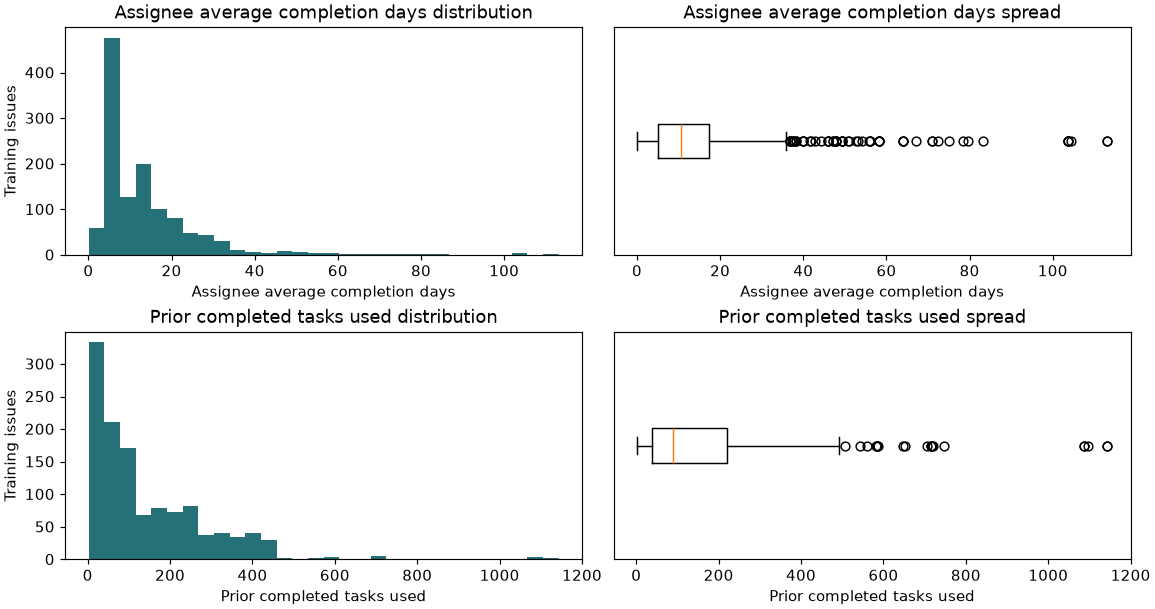

task_type (13 distinct observed labels)


,Issues,Share (%),Under 10 issues
task_type,,,
Task,342,27.99,False
Technical task,281,23.0,False
Improvement,250,20.46,False
Bug Fix,248,20.29,False
Sub-task,50,4.09,False
Feature Development,20,1.64,False
Test,7,0.57,True
Story,6,0.49,True
Documentation,5,0.41,True


Largest category for task_type: Task (342 issues).
Priority (5 distinct observed labels)


,Issues,Share (%),Under 10 issues
Priority,,,
Highest,7,0.57,True
High,18,1.47,False
Normal,830,67.92,False
Low,320,26.19,False
Lowest,47,3.85,False


Largest category for Priority: Normal (830 issues).


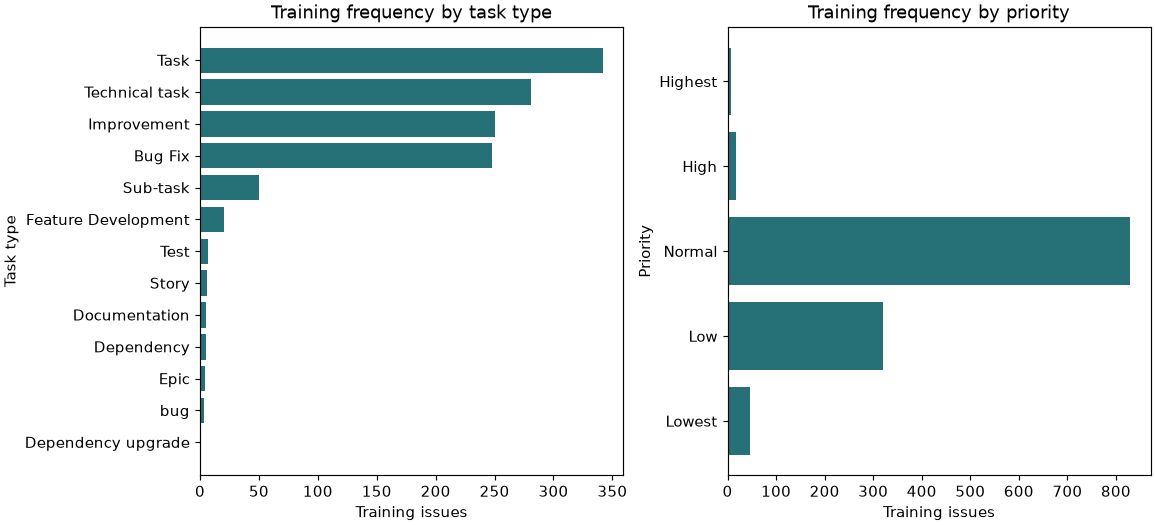

In [4]:
if train.empty:
    print("No usable training data for exploration.")
else:
    numeric_features = [
        field for field in (assignee_average, "prior_completed_tasks_used")
        if np.isfinite(train[field]).any()
    ]
    numeric_summary = train[numeric_features].replace([np.inf, -np.inf], np.nan)
    if numeric_features:
        display(numeric_summary.describe().T.assign(Skewness=numeric_summary.skew()).round(3))
        fig, axes = plt.subplots(len(numeric_features), 2, squeeze=False, figsize=(11, 2.9 * len(numeric_features)), layout="constrained")
        for (hist, box), field in zip(axes, numeric_features):
            values = numeric_summary[field].dropna()
            label = field.replace("_", " ").capitalize()
            hist.hist(values, bins=30, color="#267078")
            hist.set(title=f"{label} distribution", xlabel=label, ylabel="Training issues")
            box.boxplot(values, orientation="horizontal")
            box.set(title=f"{label} spread", xlabel=label, yticks=[])
        plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
    for ax, field in zip(axes, group_cols):
        counts_for_field = train[field].fillna("(missing)").value_counts()
        if field == "Priority":
            order = [label for label in priority_order if label in counts_for_field.index]
            order.extend(counts_for_field.index.difference(order))
            counts_for_field = counts_for_field.reindex(order)
        frequency = counts_for_field.rename("Issues").to_frame()
        frequency["Share (%)"] = counts_for_field.div(len(train)).mul(100)
        frequency["Under 10 issues"] = counts_for_field.lt(10)
        print(field, f"({train[field].nunique()} distinct observed labels)")
        display(frequency.round(2))
        bars = counts_for_field.iloc[::-1]
        ax.barh(bars.index, bars, color="#267078")
        ax.set(title=f"Training frequency by {field.replace('_', ' ').lower()}", xlabel="Training issues", ylabel=field.replace("_", " ").capitalize())
        print(f"Largest category for {field}: {counts_for_field.idxmax()} ({counts_for_field.max():,} issues).")
    plt.show()

Learn the category list from the training data. Review uncommon labels for spelling differences before joining any categories. Use validation data to check which categories help predict duration.

## 6. Understand completion duration

Compare the original duration in days with a `log1p` view, which takes the logarithm of one plus the duration. This keeps zero-day values and makes the many shorter tasks easier to see on the chart.

,Value
count,1222.000
mean,9.508
std,33.492
min,0.000
1%,0.000
5%,0.001
25%,0.101
50%,0.854
75%,5.172
90%,19.145


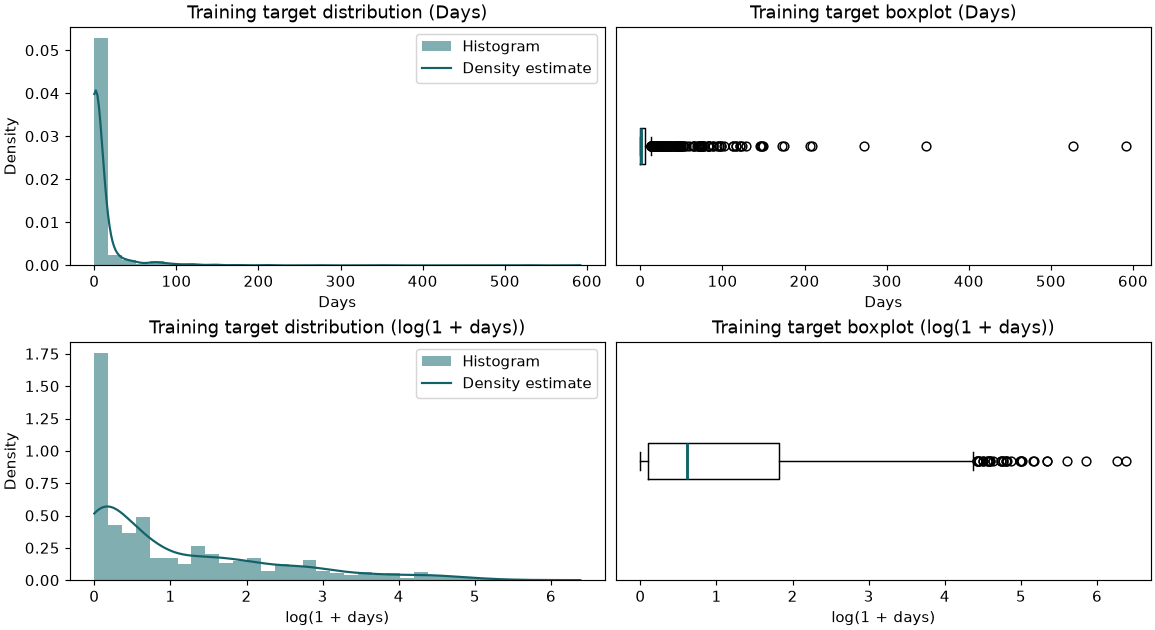

Training mean is 9.51 days and median is 0.85 days.
Skewness is 9.85 in days and 1.29 after log1p.


In [5]:
train_duration = train[target].dropna()
target_summary = pd.Series(dtype=float)
if train_duration.empty:
    print("No usable training targets.")
else:
    log_duration = np.log1p(train_duration)
    target_summary = train_duration.describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    target_summary.loc["Skewness"] = train_duration.skew()
    target_summary.loc["Excess kurtosis"] = train_duration.kurt()
    target_summary.loc["Zero-day training durations"] = train_duration.eq(0).sum()
    target_summary.loc["Negative target rows in source audit"] = df[target].lt(0).sum()
    target_summary.loc["Above training P99"] = train_duration.gt(train_duration.quantile(0.99)).sum()
    display(target_summary.round(3).rename("Value").to_frame())

    fig, axes = plt.subplots(2, 2, figsize=(11, 6), layout="constrained")
    for (density, box), (values, label) in zip(axes, [(train_duration, "Days"), (log_duration, "log(1 + days)")]):
        if sns is not None:
            sns.histplot(values, bins=35, stat="density", kde=values.nunique() > 1, ax=density, color="#267078")
        else:
            density.hist(values, bins=35, density=True, color="#80aeb1", label="Histogram")
            if len(values) > 1 and values.std() > 0:
                # Gaussian kernel density estimate with Scott bandwidth.
                bandwidth = values.std() * len(values) ** (-0.2)
                x = np.linspace(0, max(values.max(), bandwidth), 320)
                offsets = (x[:, None] - values.to_numpy()) / bandwidth
                kernel_density = np.exp(-0.5 * offsets ** 2).mean(axis=1) / (bandwidth * np.sqrt(2 * np.pi))
                density.plot(x, kernel_density, color="#146269", label="Density estimate")
                density.legend()
        density.set(title=f"Training target distribution ({label})", xlabel=label, ylabel="Density")
        box.boxplot(values, orientation="horizontal", medianprops={"color": "#146269", "linewidth": 2})
        box.set(title=f"Training target boxplot ({label})", xlabel=label, yticks=[])
    plt.show()

    print(f"Training mean is {train_duration.mean():.2f} days and median is {train_duration.median():.2f} days.")
    print(f"Skewness is {train_duration.skew():.2f} in days and {log_duration.skew():.2f} after log1p.")

The mean is much higher than the median because a few tasks take a long time. Compare models trained on original days and on `log1p`. Convert both sets of predictions to days before scoring and check the errors for long tasks separately.

## 7. Review unusual durations

Use the 1.5 × IQR rule to flag unusual durations. The IQR is the width of the middle half of the values. Also check the tasks above the 95th and 99th percentiles. Use a separate rule for each task type with at least 10 training tasks and compare the longest durations with the recorded start and resolution dates.

In [6]:
def duration_fences(durations):
    q1, q3 = durations.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

outlier_lower, outlier_upper = duration_fences(train[target])
outlier_mask = train[target].lt(outlier_lower) | train[target].gt(outlier_upper)
outlier_total = int(outlier_mask.sum())

if train.empty:
    print("Outlier checks require a usable training split.")
else:
    p95, p99 = train[target].quantile([0.95, 0.99])
    tail_summary = pd.DataFrame({
        "Threshold (days)": [outlier_lower, outlier_upper, p95, p99],
        "Issues beyond threshold": [
            train[target].lt(outlier_lower).sum(), train[target].gt(outlier_upper).sum(),
            train[target].gt(p95).sum(), train[target].gt(p99).sum(),
        ],
    }, index=["Below lower IQR fence", "Above upper IQR fence", "Above 95th percentile", "Above 99th percentile"])
    display(tail_summary.round(2))

    type_rows = []
    for task_type, durations in train.groupby("task_type")[target]:
        if len(durations) < 10:
            continue
        lower, upper = duration_fences(durations)
        flagged = (durations.lt(lower) | durations.gt(upper)).sum()
        type_rows.append({
            "Task type": task_type, "Issues": len(durations), "Lower fence (days)": lower,
            "Upper fence (days)": upper, "Outliers": flagged, "Without outliers": len(durations) - flagged,
        })
    if type_rows:
        display(pd.DataFrame(type_rows).set_index("Task type").sort_values("Issues", ascending=False).round(2))
    else:
        print("No task type has at least 10 training issues.")

    longest = train.nlargest(8, target)[["issue_key", *group_cols, target, start_col, "Resolved"]].copy()
    longest["Elapsed days from timestamps"] = (
        longest["Resolved"] - longest[start_col]
    ).dt.total_seconds().div(86_400)
    comparable = longest["Elapsed days from timestamps"].notna()
    consistent = comparable & longest[target].sub(longest["Elapsed days from timestamps"]).abs().le(1e-6)
    longest["Timestamp check"] = np.select(
        [consistent, comparable], ["Matches recorded duration", "Review duration mismatch"],
        default="Missing timestamp",
    )
    display(longest.round({target: 3, "Elapsed days from timestamps": 3}))
    print(f"The IQR rule flagged {outlier_total:,} of {len(train):,} training issues.")
    print(f"Of the {len(longest)} longest issues, {consistent.sum()} match the recorded timestamp interval.")

,Threshold (days),Issues beyond threshold
Below lower IQR fence,-7.50,0
Above upper IQR fence,12.78,179
Above 95th percentile,47.06,62
Above 99th percentile,127.69,13


,Issues,Lower fence (days),Upper fence (days),Outliers,Without outliers
Task type,,,,,
Task,342,-5.92,10.02,48,294
Technical task,281,-4.93,8.81,32,249
Improvement,250,-16.28,27.50,28,222
Bug Fix,248,-5.86,9.89,39,209
Sub-task,50,-11.84,20.07,9,41
Feature Development,20,-59.98,101.44,2,18


,issue_key,task_type,Priority,actual_completion_duration_days,actual_start_date,Resolved,Elapsed days from timestamps,Timestamp check
1208,SLING-12261,Improvement,Normal,591.923,2024-03-01 16:21:00.511+00:00,2025-10-14 14:30:45.642+00:00,591.923,Matches recorded duration
52,OAK-10674,Task,Normal,526.790,2024-03-05 14:51:56.460+00:00,2025-08-14 09:50:09.430+00:00,526.790,Matches recorded duration
1292,SLING-12539,Improvement,Normal,348.335,2024-12-11 09:05:37.794+00:00,2025-11-24 17:08:30.536+00:00,348.335,Matches recorded duration
1338,SLING-12624,Improvement,Normal,272.190,2025-01-17 16:28:38.373+00:00,2025-10-16 21:02:26.111+00:00,272.190,Matches recorded duration
92,OAK-10759,Documentation,Low,209.114,2024-04-10 10:34:41.541+00:00,2024-11-05 13:19:24.641+00:00,209.114,Matches recorded duration
190,OAK-11001,Task,Low,206.887,2024-08-02 12:10:20.898+00:00,2025-02-25 09:27:10.853+00:00,206.887,Matches recorded duration
210,OAK-11047,Epic,Highest,174.990,2024-08-20 15:06:43.257+00:00,2025-02-11 14:52:10.815+00:00,174.990,Matches recorded duration
84,OAK-10741,Improvement,Normal,173.041,2024-04-04 05:50:25.579+00:00,2024-09-24 06:48:52.043+00:00,173.041,Matches recorded duration


The IQR rule flagged 179 of 1,222 training issues.
Of the 8 longest issues, 8 match the recorded timestamp interval.


A long duration may reflect a difficult task, a blocker, or a delay in updating the tracker. Review the issue history when possible. Keep valid long durations and check how well the model predicts them.

## 8. Compare features with completion duration

First compare durations by priority and task type. Then use scatter plots to check historical assignee averages, prior completed tasks, and text length. Pearson measures how closely two values follow a straight-line pattern. Spearman checks whether higher values of one tend to go with higher or lower values of the other.

,Issues,Mean,Median
Priority,,,
Highest,7,45.30,2.25
High,18,4.60,0.29
Normal,830,10.56,0.99
Low,320,6.80,0.56
Lowest,47,5.83,0.25


,Issues,Mean,Median
task_type,,,
Task,342,8.71,0.65
Technical task,281,3.78,0.82
Improvement,250,14.23,1.87
Bug Fix,248,7.33,0.68
Sub-task,50,12.13,0.99
Feature Development,20,27.70,1.89
Test,7,29.94,4.32
Story,6,2.77,3.02
Dependency,5,1.01,0.81


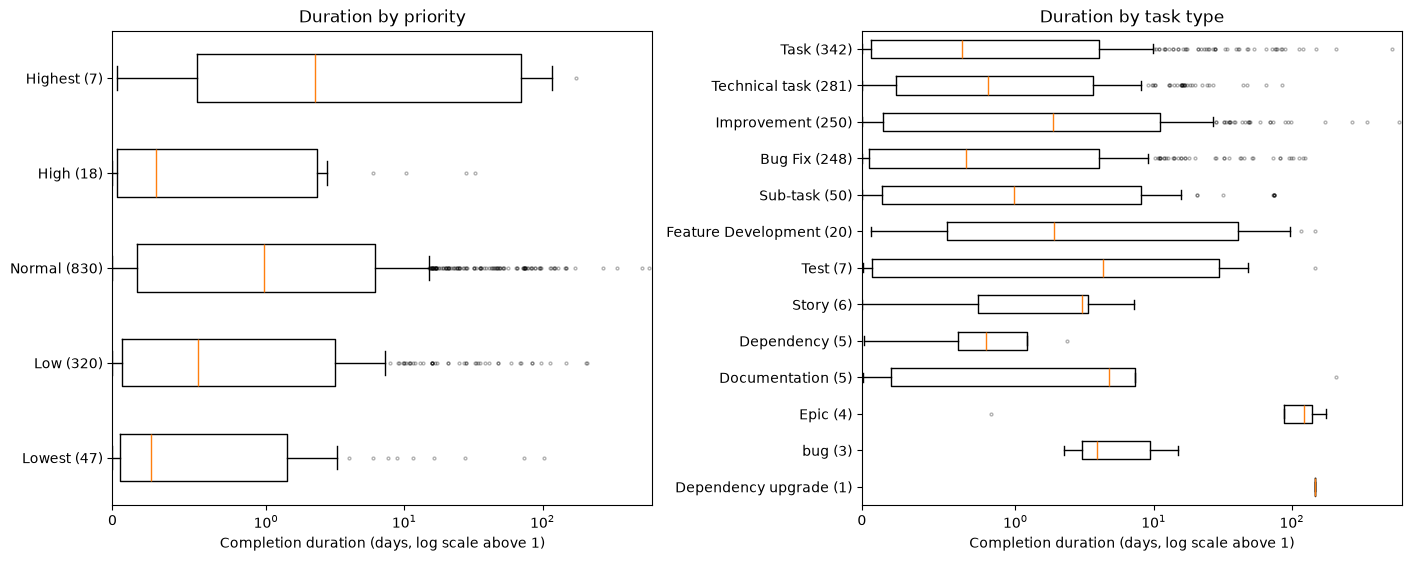

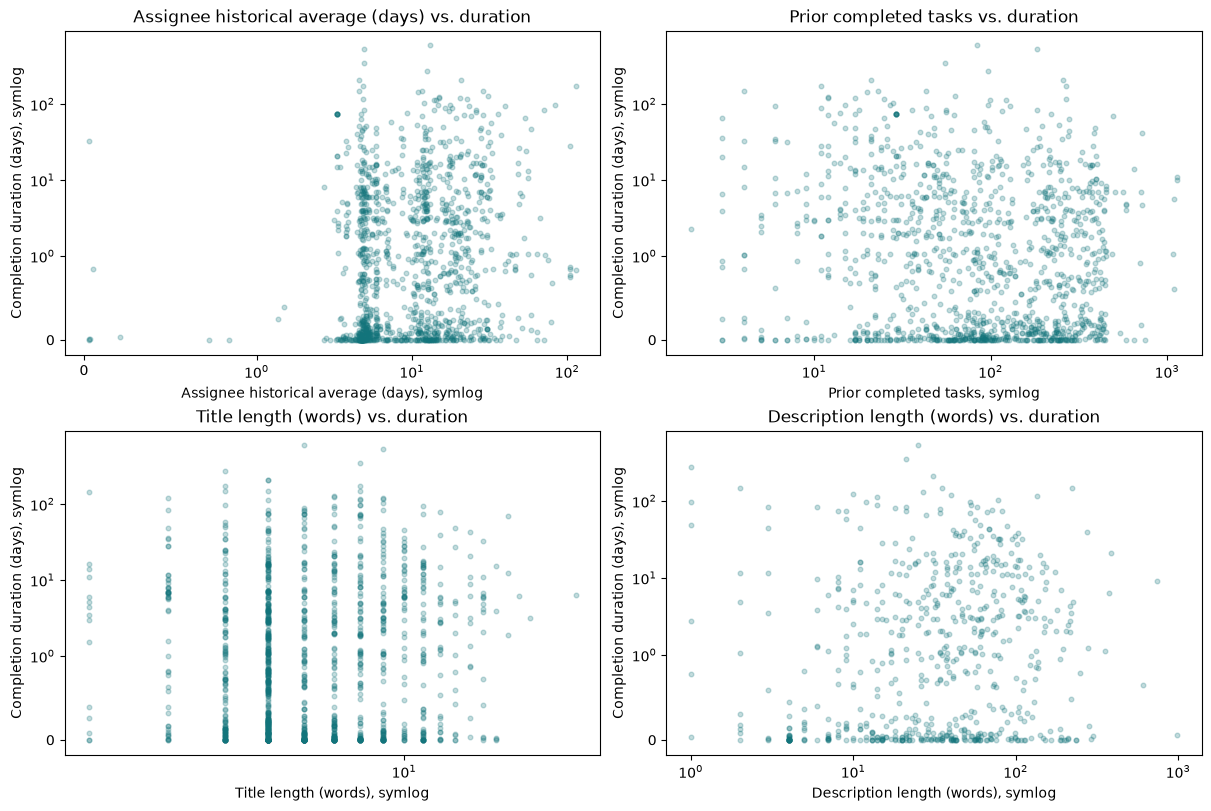

,Pairs,Pearson,Spearman
Feature,,,
Assignee historical average (days),1222,0.066,0.156
Prior completed tasks,1222,-0.074,-0.099
Title length (words),1222,0.014,0.037
Description length (words),638,-0.037,0.177


,Issues,Median
actual_start_date,,
Monday,242,0.78
Tuesday,245,0.87
Wednesday,206,0.84
Thursday,208,0.74
Friday,225,0.83
Saturday,34,2.10
Sunday,62,1.20


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), layout="constrained")
for ax, column, title in zip(
    axes, ["Priority", "task_type"], ["Duration by priority", "Duration by task type"],
):
    groups = train.groupby(column)[target]
    summary = groups.agg(Issues="size", Mean="mean", Median="median")
    print(title)
    if summary.empty:
        ax.set(title=title, xlabel="Completion duration (days)")
        ax.text(0.5, 0.5, "No training data", transform=ax.transAxes, ha="center")
        continue

    if column == "Priority":
        rank = {label: position for position, label in enumerate(priority_order)}
        ordering = sorted(summary.index, key=lambda label: rank.get(label, len(rank)))
        summary = summary.reindex(ordering)
    else:
        summary = summary.sort_values("Issues", ascending=False)

    display(summary.round(2))
    ax.boxplot(
        [groups.get_group(label) for label in summary.index],
        orientation="horizontal",
        tick_labels=[f"{label} ({count})" for label, count in summary["Issues"].items()],
        flierprops={"markersize": 2, "alpha": 0.3},
    )
    ax.invert_yaxis()
    ax.set_xscale("symlog", linthresh=1)
    ax.set(title=title, xlabel="Completion duration (days, log scale above 1)", xlim=(0, None))
    supported = summary.loc[summary["Issues"].ge(10), "Median"]
    if len(supported) >= 2:
        print(
            f"Medians among groups with at least 10 issues range from "
            f"{supported.min():.2f} days ({supported.idxmin()}) to "
            f"{supported.max():.2f} days ({supported.idxmax()})."
        )
plt.show()

relationship_features = {
    "Assignee historical average (days)": train["assignee_average_completion_days"],
    "Prior completed tasks": train["prior_completed_tasks_used"],
    "Title length (words)": train["title"].str.count(r"\S+"),
    "Description length (words)": train["Description"].str.count(r"\S+"),
}
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
correlation_rows = []
for (feature, values), ax in zip(relationship_features.items(), axes.flat, strict=True):
    pairs = pd.DataFrame({"Feature": values, "Duration": train[target]}).dropna()
    pairs = pairs.loc[np.isfinite(pairs.astype(float)).all(axis=1)]
    pearson = np.nan
    spearman = np.nan
    if len(pairs) > 1 and pairs.nunique().min() > 1:
        pearson = pairs.corr().iat[0, 1]
        spearman = pairs.rank().corr().iat[0, 1]
    correlation_rows.append({"Feature": feature, "Pairs": len(pairs), "Pearson": pearson, "Spearman": spearman})
    if pairs.empty:
        ax.text(0.5, 0.5, "No observed pairs", transform=ax.transAxes, ha="center")
    else:
        ax.scatter(pairs["Feature"], pairs["Duration"], s=11, alpha=0.25, color="#12747b")
        ax.set_xscale("symlog", linthresh=1)
        ax.set_yscale("symlog", linthresh=1)
    ax.set(title=f"{feature} vs. duration", xlabel=f"{feature}, symlog", ylabel="Completion duration (days), symlog")
plt.show()
bivariate_corr = pd.DataFrame(correlation_rows).set_index("Feature")
display(bivariate_corr.round(3))

ranked = bivariate_corr["Spearman"].dropna()
if not ranked.empty:
    strongest = ranked.abs().idxmax()
    print(f"Largest absolute Spearman association: {strongest}, {ranked.at[strongest]:.2f}.")

weekday = train[start_col].dt.day_name()
weekday_summary = train.groupby(weekday)[target].agg(Issues="size", Median="median")
if not weekday_summary.empty:
    print("Completion duration by actual start weekday")
    weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    display(weekday_summary.reindex(weekday_order).round(2))
    busiest = weekday_summary["Issues"].idxmax()
    print(f"The busiest actual start weekday in training was {busiest}, with {weekday_summary.at[busiest, 'Issues']:,} issues.")

Differences in duration can reflect the kinds of tasks each group contains. Verify the stored assignee average and prior task count against earlier completions before using them for prediction (Section 12). See Section 11 for trends over time.

### Heatmap of relationships between fields

Each square compares two fields using training tasks that have both values. The heatmap uses word counts for `title` and `Description`. It treats `Created` and `Resolved` as days since a common date.

- Two numbers use **absolute Spearman correlation** to check how closely their ranks move together.
- A category and a number use the **correlation ratio (η)** to check how much values differ between groups.
- Two categories use **bias-corrected Cramér’s V** to check how often their labels occur together.

Darker squares show stronger relationships. A dash means there are too few values or too little variation. Many small assignee groups can make the correlation ratio look stronger. Use `Resolved` for data checks only because it becomes known after the estimate.

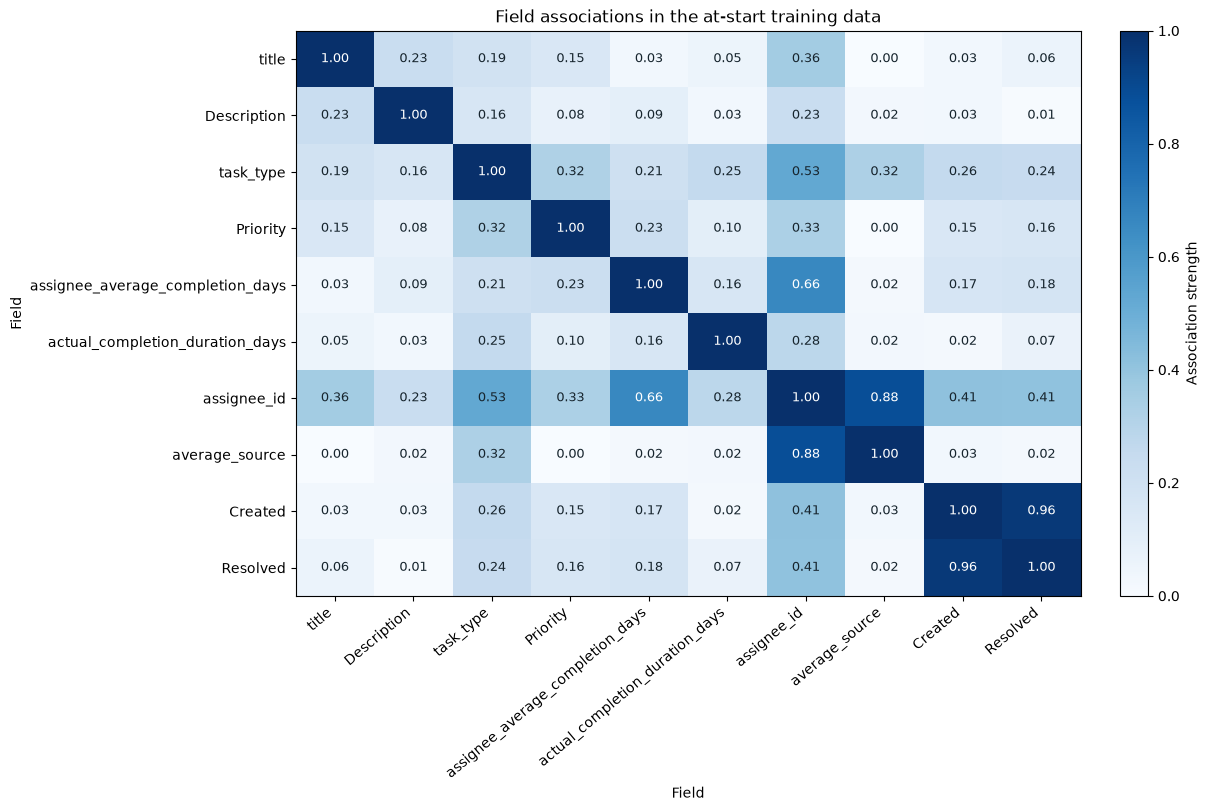

In [8]:
def association_strength(left, right, left_is_category, right_is_category):
    paired = pd.DataFrame({"left": left, "right": right}).dropna()
    if len(paired) < 3 or paired.nunique().min() < 2:
        return np.nan

    if left_is_category and right_is_category:
        table = pd.crosstab(paired["left"], paired["right"]).to_numpy()
        size = table.sum()
        rows, columns = table.shape
        expected = np.outer(table.sum(axis=1), table.sum(axis=0)) / size
        phi_squared = (((table - expected) ** 2 / expected).sum()) / size
        corrected = max(0, phi_squared - (rows - 1) * (columns - 1) / (size - 1))
        denominator = min(
            rows - 1 - (rows - 1) ** 2 / (size - 1),
            columns - 1 - (columns - 1) ** 2 / (size - 1),
        )
        return np.sqrt(corrected / denominator) if denominator > 0 else np.nan

    if left_is_category or right_is_category:
        label, value = ("left", "right") if left_is_category else ("right", "left")
        group_stats = paired.groupby(label)[value].agg(["size", "mean"])
        values = paired[value]
        between_groups = (group_stats["size"] * (group_stats["mean"] - values.mean()) ** 2).sum()
        total_variation = ((values - values.mean()) ** 2).sum()
        return np.sqrt(np.clip(between_groups / total_variation, 0, 1)) if total_variation > 0 else np.nan

    return abs(paired["left"].rank().corr(paired["right"].rank()))


if train.empty:
    print("A usable training window is required for the field association heatmap.")
else:
    heatmap_fields = [
        "title", "Description", "task_type", "Priority", "assignee_average_completion_days",
        "actual_completion_duration_days", "assignee_id", "average_source", "Created", "Resolved",
    ]
    category_fields = {"task_type", "Priority", "assignee_id", "average_source"}
    heatmap_data = train[heatmap_fields].copy()
    for field in ("title", "Description"):
        heatmap_data[field] = heatmap_data[field].str.count(r"S+")
    for field in ("Created", "Resolved"):
        heatmap_data[field] = (heatmap_data[field] - pd.Timestamp("1970-01-01", tz="UTC")) / pd.Timedelta(days=1)
    for field in ("assignee_average_completion_days", "actual_completion_duration_days"):
        heatmap_data[field] = heatmap_data[field].where(np.isfinite(heatmap_data[field]))

    associations = pd.DataFrame(np.nan, index=heatmap_fields, columns=heatmap_fields)
    for row, left in enumerate(heatmap_fields):
        for right in heatmap_fields[row:]:
            if left == right:
                score = 1.0 if heatmap_data[left].count() >= 3 and heatmap_data[left].nunique() >= 2 else np.nan
            else:
                score = association_strength(
                    heatmap_data[left], heatmap_data[right],
                    left in category_fields, right in category_fields,
                )
            associations.at[left, right] = associations.at[right, left] = score

    fig, ax = plt.subplots(figsize=(12, 8), layout="constrained")
    cmap = plt.get_cmap("Blues").with_extremes(bad="#eeeeee")
    image = ax.imshow(associations.to_numpy(), vmin=0, vmax=1, cmap=cmap, aspect="auto")
    ax.set_xticks(range(len(heatmap_fields)), heatmap_fields, rotation=40, ha="right")
    ax.set_yticks(range(len(heatmap_fields)), heatmap_fields)
    ax.set(title="Field associations in the at-start training data", xlabel="Field", ylabel="Field")
    for row, scores in enumerate(associations.to_numpy()):
        for column, score in enumerate(scores):
            label = "—" if pd.isna(score) else f"{score:.2f}"
            ax.text(column, row, label, color="white" if score >= 0.60 else "#17252e",
                    ha="center", va="center", fontsize=9)
    fig.colorbar(image, ax=ax, label="Association strength")
    plt.show()

## 9. Compare task type and priority combinations

Count every possible pairing of the task types and priorities in the export. **Coverage** is the percentage of possible pairs with at least one task. Use the full export to count pairs and training data to compare durations.

In [9]:
from itertools import product

very_rare_max = 9
rare_max = 29
minimum_group_plot_size = 10

actual_types = df["task_type"].dropna().value_counts().index.tolist()
observed_priorities = df["Priority"].dropna().unique().tolist()
actual_priorities = [label for label in priority_order if label in observed_priorities]
actual_priorities += sorted(set(observed_priorities) - set(actual_priorities))
pair_index = pd.MultiIndex.from_tuples(list(product(actual_types, actual_priorities)), names=group_cols)

print(f"Task types ({len(actual_types)} observed, 14 expected): {', '.join(actual_types) or 'none'}")
print(f"Priorities ({len(actual_priorities)} observed, 5 expected): {', '.join(actual_priorities) or 'none'}")
if (len(actual_types), len(actual_priorities)) != (14, 5):
    print("The observed category counts differ from the expected 14 × 5 grid. The audit uses the actual labels.")

complete_pairs = df.dropna(subset=group_cols)
export_counts = complete_pairs.groupby(group_cols).size().reindex(pair_index, fill_value=0)
train_grouped = train.groupby(group_cols)[target]
training_counts = train_grouped.size().reindex(pair_index, fill_value=0)
combination_stats = train_grouped.agg(
    Mean="mean", Median="median", SD="std", Minimum="min", Maximum="max",
).reindex(pair_index)

def support_band(counts):
    return pd.cut(
        counts, bins=[-1, 0, very_rare_max, rare_max, np.inf],
        labels=["Missing", "Very rare", "Rare", "Better represented"],
    )

def coverage(counts):
    return 100 * counts.gt(0).mean() if len(counts) else np.nan

theoretical_count = len(pair_index)
observed_count = int(export_counts.gt(0).sum())
missing_count = theoretical_count - observed_count
very_rare_count = int(export_counts.between(1, very_rare_max).sum())
rare_count = int(export_counts.between(very_rare_max + 1, rare_max).sum())
combination_coverage = coverage(export_counts)
training_observed_count = int(training_counts.gt(0).sum())
training_missing_count = theoretical_count - training_observed_count
training_very_rare_count = int(training_counts.between(1, very_rare_max).sum())
training_rare_count = int(training_counts.between(very_rare_max + 1, rare_max).sum())
training_combination_coverage = coverage(training_counts)

coverage_summary = pd.DataFrame({
    "Full export": [theoretical_count, observed_count, missing_count, very_rare_count, rare_count,
                    observed_count - very_rare_count - rare_count, combination_coverage],
    "Training": [theoretical_count, training_observed_count, training_missing_count,
                 training_very_rare_count, training_rare_count,
                 training_observed_count - training_very_rare_count - training_rare_count, training_combination_coverage],
}, index=["Theoretical pairs", "Observed pairs", "Missing", "Very rare", "Rare", "Better represented", "Coverage (%)"])
display(coverage_summary.round(1))

def share(counts):
    total = counts.sum()
    return counts.div(total).mul(100) if total else counts.astype(float).mask(counts.eq(0))

pair_summary = pd.DataFrame({
    "Export issues": export_counts, "Export %": share(export_counts),
    "Export support": support_band(export_counts),
    "Training issues": training_counts, "Training %": share(training_counts),
    "Training support": support_band(training_counts),
}).join(combination_stats.add_suffix(" days"))
if pair_summary.empty:
    print("A combination grid requires both categorical fields.")
else:
    with pd.option_context("display.max_rows", len(pair_summary)):
        display(pair_summary.round(2))
    print("Cross-tabulation of training issue counts")
    cross_tabulation = pd.crosstab(train["task_type"], train["Priority"]).reindex(
        index=actual_types, columns=actual_priorities, fill_value=0,
    )
    display(cross_tabulation)
    print(
        f"Training covers {training_observed_count} of {theoretical_count} pairs "
        f"({training_combination_coverage:.1f}%). "
        f"{training_missing_count} pairs have zero training issues and "
        f"{training_very_rare_count + training_rare_count} have 1–{rare_max}."
    )

Task types (14 observed, 14 expected): Task, Bug Fix, Improvement, Technical task, Sub-task, Feature Development, Test, Dependency, Story, Documentation, Epic, bug, Wish, Dependency upgrade
Priorities (5 observed, 5 expected): Highest, High, Normal, Low, Lowest


,Full export,Training
Theoretical pairs,70.0,70.0
Observed pairs,41.0,38.0
Missing,29.0,32.0
Very rare,24.0,24.0
Rare,8.0,5.0
Better represented,9.0,9.0
Coverage (%),58.6,54.3


Export issues  ...  Maximum days
task_type           Priority                 ...              
Task                Highest               2  ...         22.00
                    High                 10  ...         27.85
                    Normal              280  ...        526.79
                    Low                 205  ...        206.89
                    Lowest               19  ...          3.24
Bug Fix             Highest               2  ...          0.03
                    High                 11  ...          2.76
                    Normal              306  ...        123.27
                    Low                  88  ...        113.11
                    Lowest               10  ...        101.96
Improvement         Highest               0  ...           NaN
                    High                  6  ...         32.30
                    Normal              275  ...        591.92
                    Low                  87  ...         97.79
                    Lowest               12  ...         11.57
Technical task      Highest               0  ...           NaN
                    High                  0  ...           NaN
                    Normal              239  ...         64.36
                    Low                  49  ...         84.14
                    Lowest               18  ...         16.47
Sub-task            Highest               0  ...           NaN
                    High                  1  ...           NaN
                    Normal               58  ...         74.50
                    Low                  15  ...         13.01
                    Lowest                2  ...          0.37
Feature Development Highest               1  ...          0.26
                    High                  1  ...          0.87
                    Normal               29  ...        146.66
                    Low                   1  ...          6.55
                    Lowest                0  ...           NaN
Test                Highest               0  ...           NaN
                    High                  1  ...          0.02
                    Normal                7  ...        146.05
                    Low                   2  ...          0.10
                    Lowest                0  ...           NaN
Dependency          Highest               0  ...           NaN
                    High                  0  ...           NaN
                    Normal                5  ...          2.37
                    Low                   2  ...          0.81
                    Lowest                1  ...          0.63
Story               Highest               0  ...           NaN
                    High                  0  ...           NaN
                    Normal                5  ...          7.14
                    Low                   1  ...          3.18
                    Lowest                0  ...           NaN
Documentation       Highest               0  ...           NaN
                    High                  0  ...           NaN
                    Normal                0  ...           NaN
                    Low                   5  ...        209.11
                    Lowest                1  ...           NaN
Epic                Highest               4  ...        174.99
                    High                  0  ...           NaN
                    Normal                1  ...        128.86
                    Low                   0  ...           NaN
                    Lowest                0  ...           NaN
bug                 Highest               1  ...          2.25
                    High                  0  ...           NaN
                    Normal                2  ...         15.03
                    Low                   0  ...           NaN
                    Lowest                0  ...           NaN
Wish                Highest               0  ...           NaN
                    High                  0  ...           Na

Cross-tabulation of training issue counts


Priority,Highest,High,Normal,Low,Lowest
task_type,,,,,
Task,1,7,185,137,12
Bug Fix,1,4,180,58,5
Improvement,0,5,179,55,11
Technical task,0,0,218,46,17
Sub-task,0,0,36,13,1
Feature Development,1,1,17,1,0
Test,0,1,5,1,0
Dependency,0,0,2,2,1
Story,0,0,5,1,0


Training covers 38 of 70 pairs (54.3%). 32 pairs have zero training issues and 29 have 1–29.


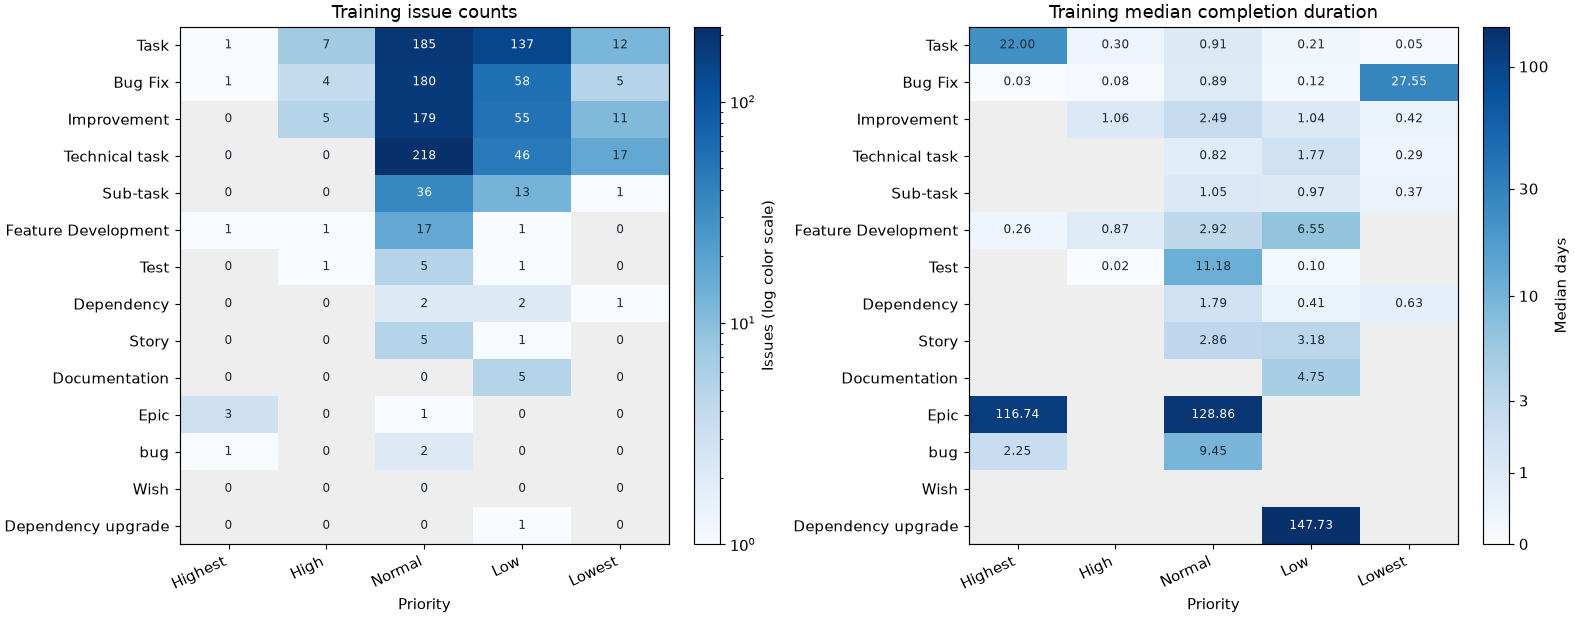

Boxplot issue counts by combination
                              Total issues  Outliers  Without outliers
Task | Lowest                           12         2                10
Bug Fix | Low                           58         7                51
Task | Low                             137        17               120
Technical task | Lowest                 17         2                15
Improvement | Lowest                    11         0                11
Technical task | Normal                218        25               193
Bug Fix | Normal                       180        31               149
Task | Normal                          185        20               165
Sub-task | Low                          13         1                12
Improvement | Low                       55         9                46
Sub-task | Normal                       36         6                30
Technical task | Low                    46         4                42
Improvement | Normal                   17

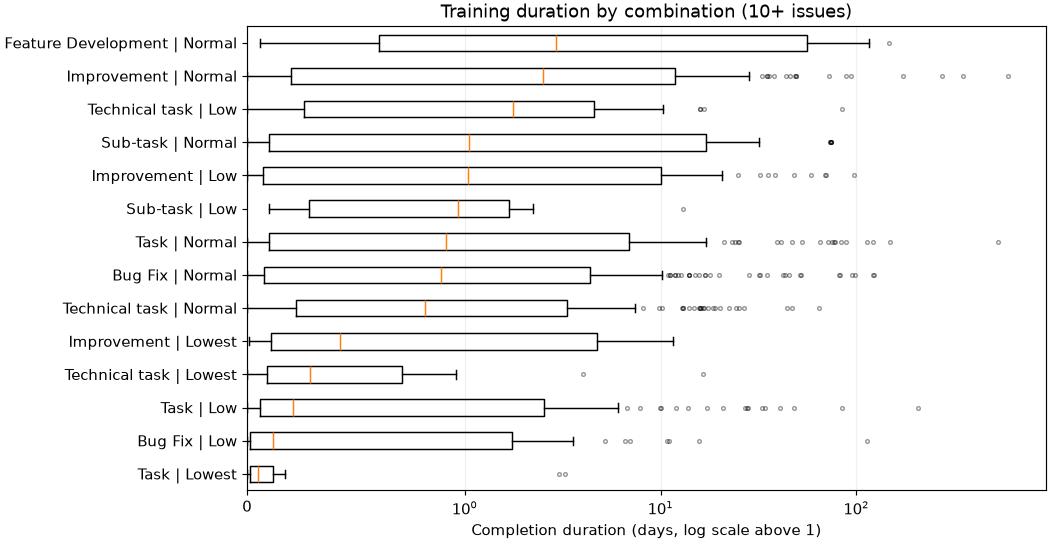

In [10]:
if not theoretical_count:
    print("Both category fields are required for the heatmaps and combination boxplots.")
elif train.empty:
    print("A usable training window is required for the heatmaps and combination boxplots.")
else:
    from matplotlib.colors import LogNorm

    count_grid = training_counts.unstack().reindex(index=actual_types, columns=actual_priorities)
    median_grid = combination_stats["Median"].unstack().reindex_like(count_grid)
    figure_specs = [
        (count_grid, count_grid.where(count_grid.gt(0)), "Training issue counts", "Issues (log color scale)",
         LogNorm(vmin=1, vmax=max(2, int(training_counts.max()))), ",.0f"),
        (median_grid, np.log1p(median_grid), "Training median completion duration", "Median days",
         None, ".2f"),
    ]
    fig, axes = plt.subplots(1, 2, figsize=(15, max(5.7, len(actual_types) * 0.42)), layout="constrained")
    for ax, (numbers, shades, title, legend, norm, format_spec) in zip(axes, figure_specs):
        cmap = plt.get_cmap("Blues").with_extremes(bad="#eeeeee")
        image = ax.imshow(shades.to_numpy(dtype=float, na_value=np.nan), aspect="auto", cmap=cmap, norm=norm)
        ax.set(title=title, xlabel="Priority")
        ax.set_xticks(range(len(actual_priorities)), actual_priorities, rotation=25, ha="right")
        ax.set_yticks(range(len(actual_types)), actual_types)
        colorbar = fig.colorbar(image, ax=ax, label=legend)
        if norm is None:
            ticks = [x for x in (0, 1, 3, 10, 30, 100) if np.log1p(x) <= image.norm.vmax]
            colorbar.set_ticks(np.log1p(ticks), labels=ticks)
        for row, row_values in enumerate(numbers.to_numpy()):
            for column, value in enumerate(row_values):
                if pd.isna(value):
                    continue
                shade = shades.iat[row, column]
                ink = "white" if pd.notna(shade) and image.norm(shade) > 0.65 else "#1a2734"
                ax.text(column, row, format(value, format_spec), ha="center", va="center", color=ink, fontsize=8)
    plt.show()

    plot_pairs = combination_stats.loc[training_counts.ge(minimum_group_plot_size), "Median"].sort_values().index
    if len(plot_pairs):
        duration_groups = [train_grouped.get_group(pair) for pair in plot_pairs]
        plot_labels = [f"{task_type} | {priority}" for task_type, priority in plot_pairs]
        fig, ax = plt.subplots(figsize=(10, max(4.5, len(plot_pairs) * 0.37)), layout="constrained")
        plotted = ax.boxplot(
            duration_groups, orientation="horizontal", tick_labels=plot_labels, whis=1.5, showfliers=True,
            flierprops={"markersize": 2.5, "alpha": 0.4},
        )
        ax.set_xscale("symlog", linthresh=1)
        ax.set(
            title=f"Training duration by combination ({minimum_group_plot_size}+ issues)",
            xlabel="Completion duration (days, log scale above 1)", xlim=(0, None),
        )
        ax.grid(axis="x", alpha=0.2)
        pair_outliers = pd.DataFrame({
            "Total issues": [len(group) for group in duration_groups],
            "Outliers": [len(flier.get_xdata()) for flier in plotted["fliers"]],
        }, index=plot_labels)
        pair_outliers["Without outliers"] = pair_outliers["Total issues"] - pair_outliers["Outliers"]
        pair_outliers.loc["All plotted pairs"] = pair_outliers.sum()
        print("Boxplot issue counts by combination")
        print(pair_outliers.to_string())
        plt.show()
    else:
        print(f"No training combination has at least {minimum_group_plot_size} issues.")

Empty counts mark pairs with no recorded tasks. Their durations are blank because there is no estimate to show. The project documents no rules that forbid specific pairs. Keep task type and priority as separate inputs and compare prediction errors for common, rare, and unseen pairs. The count groups help plan those checks.

## 10. Check titles and descriptions

Use training rows to count missing and repeated text and check whether longer text goes with longer tasks. For repeated text, ignore case and extra whitespace. Mark possible links, markup, code, and outcome notes for review. Cleaning may have removed some formatting.

,Missing,Empty or whitespace,Available (%),Rows with repeated text,HTML,Markdown,URL,Code-like,Outcome wording
Field,,,,,,,,,
title,0,0,100.0,27,0,0,0,0,0
Description,0,584,52.2,44,32,11,182,85,5


,count,mean,std,min,25%,50%,75%,95%,max
title characters,1222.0,52.1,20.5,15.0,38.0,48.0,63.0,91.0,157.0
title words,1222.0,6.7,2.8,2.0,5.0,6.0,8.0,12.0,24.0
Description characters,638.0,653.4,1327.1,6.0,123.0,288.5,626.5,2589.3,19671.0
Description words,638.0,57.4,76.2,1.0,15.0,37.0,70.8,187.1,988.0


Paired rows  Pearson r  Spearman ρ
Field       Length unit                                    
title       Characters          1222     -0.007       0.045
            Words               1222      0.014       0.037
Description Characters           638     -0.025       0.149
            Words                638     -0.037       0.177

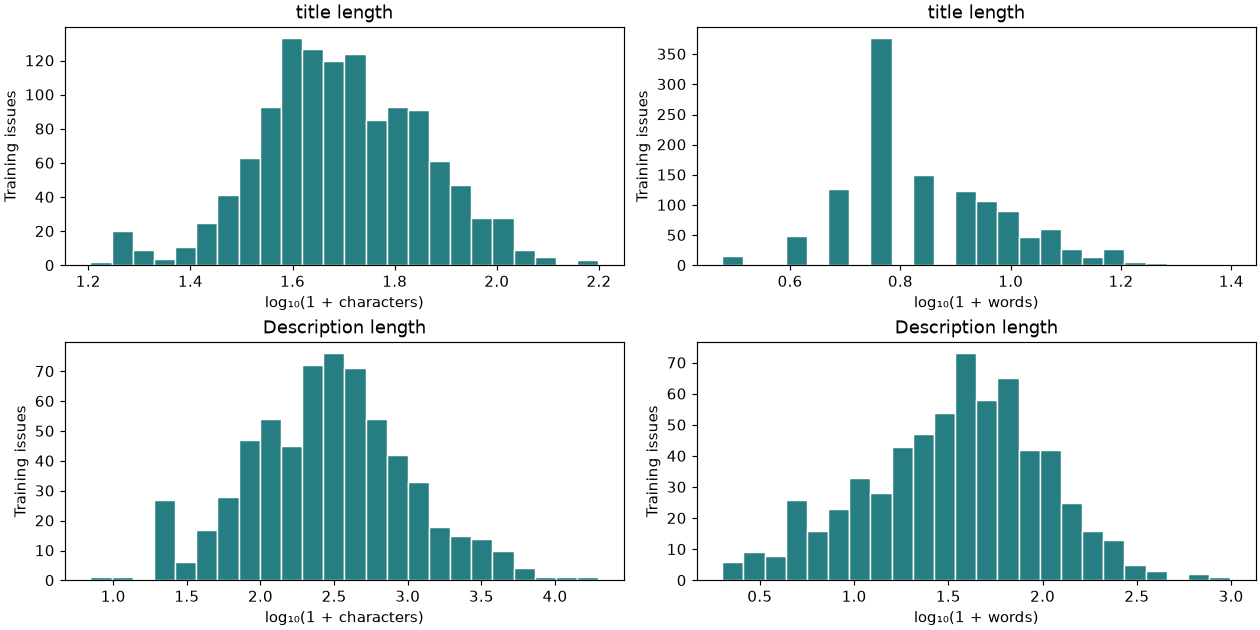

title: 100.0% available, 27 rows with repeated text, 0 flagged for outcome wording.
Description: 52.2% available, 44 rows with repeated text, 5 flagged for outcome wording.
Largest absolute rank correlation: Description words and duration (ρ=0.18).


In [11]:
text_fields = [field for field in ("title", "Description") if field in available_columns]
text_lengths = pd.DataFrame(index=train.index)
text_audit_rows = []
text_relationship_rows = []
text_patterns = {
    "HTML": r"</?[A-Za-z][A-Za-z0-9-]*(?:\s[^<>]*)?\s*/?>",
    "Markdown": r"\[[^\]]+\]\([^)]+\)|\*\*[^*]+\*\*|(?m:^\s{0,3}(?:#{1,6}\s|>\s|[-*+]\s))",
    "URL": r"\b(?:https?://|www\.)[^\s<>]+",
    "Code-like": r"```|`[^`]+`|\{code(?::[^}]+)?\}|<pre\b|<code\b|\b(?:Traceback|Stacktrace)\b",
    "Outcome wording": r"\b(?:fixed in|resolved by|implemented in|verified in|closed as|merged in)\b",
}

for field in text_fields:
    source = raw.loc[train.index, field].astype("string")
    stripped = source.str.strip()
    missing = source.isna()
    empty = stripped.eq("").fillna(False)
    present = stripped.mask(empty)
    normalized = present.str.replace(r"\s+", " ", regex=True).str.casefold()
    chars = present.str.len().astype(float)
    words = present.str.count(r"\S+").astype(float)
    text_lengths[f"{field} characters"] = chars
    text_lengths[f"{field} words"] = words
    text_audit_rows.append({
        "Field": field,
        "Missing": int(missing.sum()),
        "Empty or whitespace": int(empty.sum()),
        "Available (%)": 100 * present.notna().mean(),
        "Rows with repeated text": int((normalized.notna() & normalized.duplicated(keep=False)).sum()),
        **{
            name: int(present.str.contains(pattern, case=False, regex=True, na=False).sum())
            for name, pattern in text_patterns.items()
        },
    })
    for unit, length in (("Characters", chars), ("Words", words)):
        pairs = pd.DataFrame({"Length": length, "Duration": train[target]}).dropna()
        has_variation = (
            len(pairs) > 1 and pairs["Length"].nunique() > 1 and pairs["Duration"].nunique() > 1
        )
        text_relationship_rows.append({
            "Field": field,
            "Length unit": unit,
            "Paired rows": len(pairs),
            "Pearson r": pairs["Length"].corr(pairs["Duration"]) if has_variation else np.nan,
            "Spearman ρ": pairs["Length"].rank().corr(pairs["Duration"].rank()) if has_variation else np.nan,
        })

if text_audit_rows and len(train):
    text_audit = pd.DataFrame(text_audit_rows).set_index("Field")
    text_length_correlations = pd.DataFrame(text_relationship_rows).set_index(["Field", "Length unit"])
    display(text_audit.round(1))
    display(text_lengths.describe(percentiles=[0.25, 0.50, 0.75, 0.95]).T.round(1))
    display(text_length_correlations.round(3))

    fig, axes = plt.subplots(
        len(text_fields), 2, squeeze=False, figsize=(12, 3 * len(text_fields)), layout="constrained"
    )
    for row, field in enumerate(text_fields):
        for ax, unit in zip(axes[row], ("characters", "words")):
            length = text_lengths[f"{field} {unit}"].dropna()
            if length.empty:
                ax.text(0.5, 0.5, "No available text", ha="center", transform=ax.transAxes)
            else:
                ax.hist(np.log10(1 + length), bins=24, color="#267e82", edgecolor="white")
            ax.set(title=f"{field} length", xlabel=f"log₁₀(1 + {unit})", ylabel="Training issues")
    plt.show()

    for field, row in text_audit.iterrows():
        print(
            f"{field}: {row['Available (%)']:.1f}% available, "
            f"{int(row['Rows with repeated text']):,} rows with repeated text, "
            f"{int(row['Outcome wording']):,} flagged for outcome wording."
        )
    strongest = text_length_correlations["Spearman ρ"].dropna()
    if not strongest.empty:
        field, unit = strongest.abs().idxmax()
        print(f"Largest absolute rank correlation: {field} {unit.lower()} and duration (ρ={strongest.loc[(field, unit)]:.2f}).")
else:
    print("Text lengths and markup could not be analyzed because text fields or training rows are unavailable.")

Similar word counts can describe very different tasks. Repeated text can come from a shared template or related work, so check issue IDs separately. Outcome notes may have been added later. Use a saved copy from prediction time or check the edit history.

Compare a model with structured fields against one that also uses `sentence-transformers/all-MiniLM-L6-v2` to turn text into numbers. Use the same time-based validation periods. Track missing text and compare with simpler options such as word counts or TF-IDF. Check whether long descriptions get cut off by the text model.

## 11. See how tasks change over time

Use the recorded start date in UTC to compare training tasks over time. The first line chart shows how many tasks started each month. The second shows the median duration and the 90th percentile, the duration that about 90% of tasks finish within. The other charts show weekday counts and changes in priorities and task types.

,Issues,Median
Start weekday (UTC),,
Mon,242,0.78
Tue,245,0.87
Wed,206,0.84
Thu,208,0.74
Fri,225,0.83
Sat,34,2.10
Sun,62,1.20


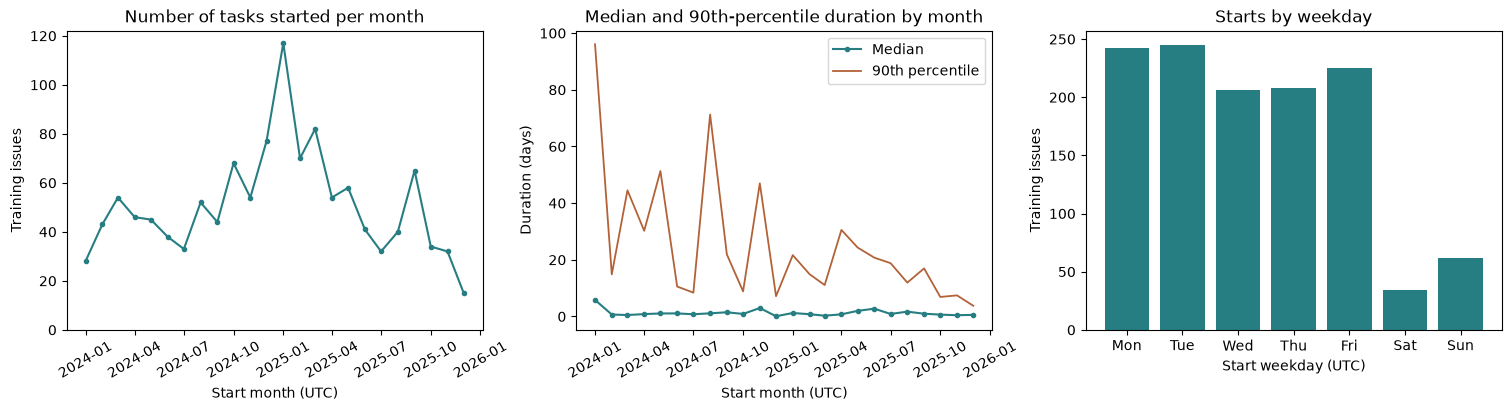

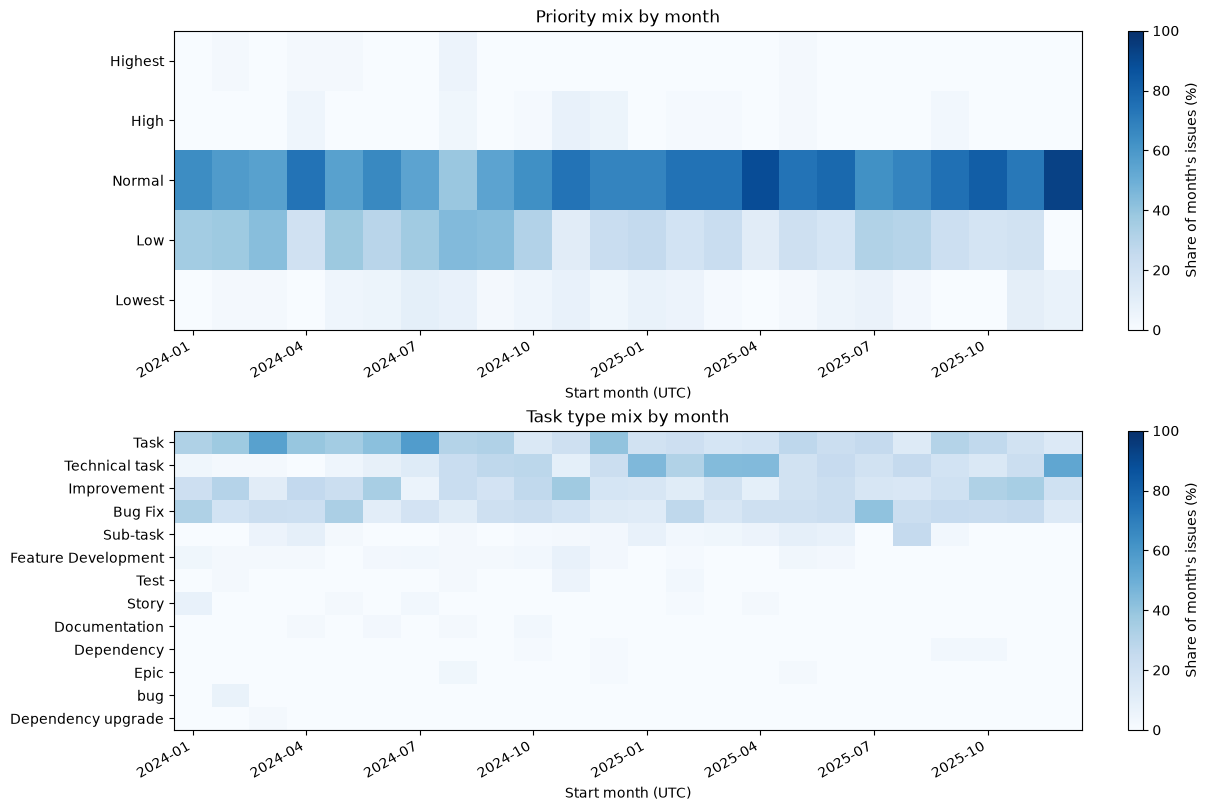

Earlier  Later  Change (pp)
Feature   Category                                        
task_type Technical task          13.2   31.9         18.6
          Task                    35.4   21.2        -14.1
Priority  Normal                  60.8   74.4         13.6
          Low                     31.8   21.1        -10.7
task_type Improvement             22.9   18.3         -4.6
          Sub-task                 2.2    5.8          3.5
          Feature Development      2.7    0.6         -2.1
Priority  High                     2.2    0.8         -1.5

In [12]:
has_train_starts = start_col in available_columns and train[start_col].notna().any()
if not has_train_starts:
    print("Calendar analysis requires usable work-start timestamps in the training window.")
else:
    calendar = train.loc[train[start_col].notna()].copy()
    start_dates = pd.to_datetime(calendar[start_col], utc=True)
    calendar["Month"] = start_dates.dt.tz_localize(None).dt.to_period("M")
    calendar["Weekday"] = start_dates.dt.day_of_week
    months = pd.period_range(calendar["Month"].min(), calendar["Month"].max(), freq="M")
    monthly = calendar.groupby("Month")[target].agg(Issues="size", Median="median", P90=lambda values: values.quantile(0.90))
    monthly = monthly.reindex(months).rename_axis("Month")
    monthly["Issues"] = monthly["Issues"].fillna(0).astype(int)

    weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
    weekdays = calendar.groupby("Weekday")[target].agg(Issues="size", Median="median").reindex(range(7))
    weekdays.index = weekday_names
    weekdays["Issues"] = weekdays["Issues"].fillna(0).astype(int)
    display(weekdays.rename_axis("Start weekday (UTC)").round(2))

    dates = months.to_timestamp()
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
    axes[0].plot(dates, monthly["Issues"], marker="o", markersize=3, color="#267e82")
    axes[0].set_ylim(bottom=0)
    axes[0].set(title="Number of tasks started per month", xlabel="Start month (UTC)", ylabel="Training issues")
    axes[1].plot(dates, monthly["Median"], marker="o", markersize=3, label="Median", color="#267e82")
    axes[1].plot(dates, monthly["P90"], linewidth=1.3, label="90th percentile", color="#b36238")
    axes[1].set(title="Median and 90th-percentile duration by month", xlabel="Start month (UTC)", ylabel="Duration (days)")
    axes[1].legend()
    for ax in axes[:2]:
        ax.tick_params(axis="x", labelrotation=30)
    axes[2].bar(weekdays.index, weekdays["Issues"], color="#267e82")
    axes[2].set(title="Starts by weekday", xlabel="Start weekday (UTC)", ylabel="Training issues")
    plt.show()

    tick_step = max(1, int(np.ceil(len(months) / 9)))
    tick_positions = list(range(0, len(months), tick_step))
    fig, axes = plt.subplots(2, 1, figsize=(12, 8), layout="constrained")
    for ax, field in zip(axes, ("Priority", "task_type")):
        labels = calendar[field].astype("string").fillna("(Missing)")
        shares = pd.crosstab(calendar["Month"], labels, normalize="index").reindex(months)
        categories = labels.value_counts().index
        if field == "Priority":
            known = [value for value in priority_order if value in categories]
            categories = known + [value for value in categories if value not in known]
        shares = shares.reindex(columns=categories)
        image = ax.imshow(
            shares.to_numpy(dtype=float).T * 100,
            aspect="auto", cmap=plt.get_cmap("Blues").with_extremes(bad="#ededed"), vmin=0, vmax=100,
        )
        ax.set_yticks(range(len(shares.columns)), shares.columns)
        ax.set_xticks(tick_positions, [str(months[pos]) for pos in tick_positions], rotation=30, ha="right")
        ax.set(title=f"{field.replace('_', ' ').capitalize()} mix by month", xlabel="Start month (UTC)")
        fig.colorbar(image, ax=ax, label="Share of month's issues (%)")
    plt.show()

    observed_months = monthly.loc[monthly["Issues"].gt(0)]
    print(
        f"Training starts span {months[0]} to {months[-1]}, with "
        f"{len(observed_months):,} months containing issues. "
        f"{weekdays['Issues'].idxmax()} has the most starts ({weekdays['Issues'].max():,})."
    )
    print(
        f"Monthly median duration ranges from {observed_months['Median'].min():.2f} to "
        f"{observed_months['Median'].max():.2f} days. Interpret this range alongside monthly counts."
    )

    if len(observed_months) > 1:
        midpoint = observed_months.index[len(observed_months) // 2]
        periods = np.where(calendar["Month"].lt(midpoint), "Earlier", "Later")
        print(f"Training category shares before and from {midpoint}")
        shifts = []
        for field in ("Priority", "task_type"):
            labels = calendar[field].astype("string").fillna("(Missing)")
            shares = (pd.crosstab(labels, periods, normalize="columns") * 100).rename_axis(columns=None)
            shares["Change (pp)"] = shares["Later"] - shares["Earlier"]
            shares.index = pd.MultiIndex.from_product([[field], shares.index], names=["Feature", "Category"])
            shifts.append(shares)
        share_shifts = pd.concat(shifts).sort_values("Change (pp)", key=lambda values: values.abs(), ascending=False)
        display(share_shifts.head(8).round(1))
        feature, category = share_shifts.index[0]
        shift = share_shifts.iloc[0]["Change (pp)"]
        print(f"{feature} category {category!r} shows the largest share change ({shift:+.1f} percentage points).")

Read the duration lines alongside the monthly counts. A month with few tasks can show a large change. The first and last months may cover only part of a month, and the export includes completed tasks.

Test calendar inputs such as month and weekday only if the source date is available when people request an estimate. Use a verified start date for estimates made at work start or the request time for earlier estimates.

## 12. Check assignee history

`assignee_id` identifies who a task was assigned to. `average_source` describes where the historical average came from, such as the assignee or the project. Rebuild histories from earlier completions to see whether they match the exported averages and counts. Also check how often a person has little or no recorded history.

Stored source on training rows


,Rows
Stored source,
assignee,1183
project,39


Stored historical average in days


,Stored mean (days)
count,1222.000
mean,13.614
std,13.296
min,0.029
25%,5.051
50%,10.493
75%,17.412
max,113.080


,Count
Distinct known training assignees,53
Training rows with missing assignee ID,0
Training rows with missing or inconsistent dates,0
Rows with known assignee but no earlier local completion,65
Rows with 1–4 earlier local assignee completions,131
Rows with 5+ earlier local assignee completions,1026
Rows with no earlier completion in pooled training history,1
Stored assignee rows with a comparable history count,1183
Comparable history counts reproduced,7
Stored assignee rows with a comparable historical mean,1141


The local as-of reconstruction reproduces 7 of 1,183 comparable assignee history counts and 3 of 1,141 comparable means.


,Paired training rows,Pearson,Spearman
Historical feature,,,
Stored mean (days),1222,0.066,0.156
Rebuilt assignee mean (days),1157,0.054,0.224


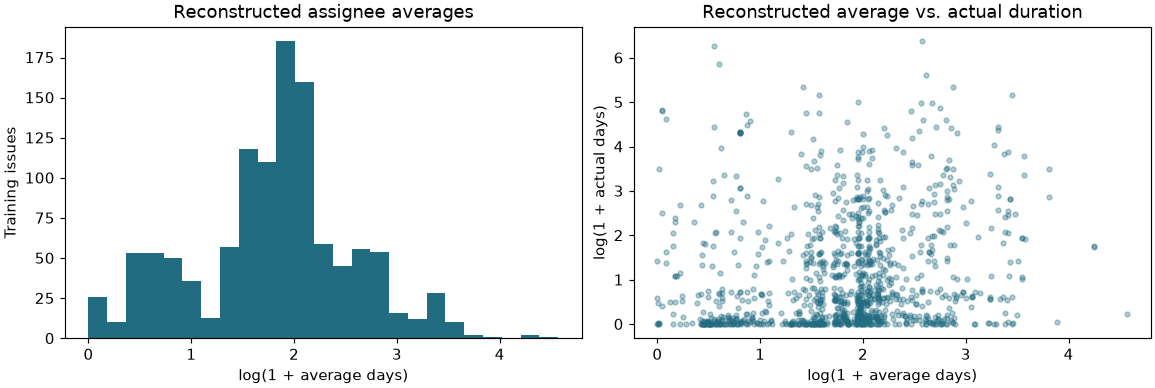

In [13]:
history_fields = {
    "assignee_id", "assignee_average_completion_days", "prior_completed_tasks_used",
    "average_source", "actual_start_date", "Resolved",
}
history_columns_present = history_fields & set(available_columns)
history_audit = pd.DataFrame(index=train.index)
history_pairs = pd.DataFrame()
assignee_history_safe = False
if train.empty:
    print("Assignee history requires usable training timestamps and durations.")
elif not history_fields <= history_columns_present:
    print("Missing fields for the full audit:", ", ".join(sorted(history_fields - history_columns_present)))
else:
    average_column = "assignee_average_completion_days"
    count_column = "prior_completed_tasks_used"
    history_audit["Stored mean (days)"] = pd.to_numeric(train[average_column], errors="coerce").astype(float)
    history_audit["Stored prior count"] = pd.to_numeric(train[count_column], errors="coerce").astype(float)
    history_audit["Stored source"] = train["average_source"]
    history_audit["Prior assignee completions"] = pd.Series(0, index=train.index, dtype="Int64")
    history_audit["Rebuilt assignee mean (days)"] = np.nan

    def earlier_completion_summary(issue_rows, completion_rows):
        # Strictly earlier finishes exclude simultaneous completions and the current task.
        completed = completion_rows.sort_values("Resolved")
        earlier_count = completed["Resolved"].searchsorted(issue_rows["actual_start_date"], side="left")
        cumulative_days = np.r_[0.0, completed[target].astype(float).cumsum().to_numpy()]
        earlier_mean = np.full(len(issue_rows), np.nan)
        np.divide(cumulative_days[earlier_count], earlier_count, out=earlier_mean, where=earlier_count > 0)
        return earlier_count, earlier_mean

    history_mean_col = "Rebuilt assignee mean (days)"
    history_count_col = "Prior assignee completions"
    ordered_dates = (
        train["actual_start_date"].notna() & train["Resolved"].notna()
        & train["Resolved"].ge(train["actual_start_date"])
    )
    history_rows = train.loc[ordered_dates].copy()
    assignee_group = history_rows.groupby("assignee_id", dropna=True)
    local_prior_counts = pd.Series(0, index=train.index, dtype="int64")
    for _, tasks in assignee_group:
        earlier_count, earlier_mean = earlier_completion_summary(tasks, tasks)
        local_prior_counts.loc[tasks.index] = earlier_count
        history_audit.loc[tasks.index, history_mean_col] = earlier_mean
    known_assignee = history_rows["assignee_id"].notna()
    history_audit[history_count_col] = local_prior_counts.where(
        known_assignee.reindex(train.index, fill_value=False)
    ).astype("Int64")
    team_count, team_mean = earlier_completion_summary(history_rows, history_rows)
    history_audit["Earlier training-pool completions"] = pd.Series(team_count, index=history_rows.index, dtype="Int64")
    history_audit["Earlier training-pool mean (days)"] = pd.Series(team_mean, index=history_rows.index)

    print("Stored source on training rows")
    display(history_audit["Stored source"].value_counts(dropna=False).rename("Rows").to_frame())
    print("Stored historical average in days")
    display(history_audit["Stored mean (days)"].describe().round(3).to_frame())

    stored_assignee = history_audit["Stored source"].eq("assignee").fillna(False)
    local_prior = history_audit[history_count_col]
    stored_count = history_audit["Stored prior count"]
    comparable_counts = stored_assignee & local_prior.notna() & stored_count.notna()
    comparable_means = stored_assignee & history_audit[history_mean_col].notna() & history_audit["Stored mean (days)"].notna()
    matched_counts = comparable_counts & local_prior.eq(stored_count)
    matched_means = comparable_means & np.isclose(
        history_audit[history_mean_col], history_audit["Stored mean (days)"], rtol=0, atol=1e-6,
    )
    assignee_audit_counts = pd.Series({
        "Distinct known training assignees": history_rows["assignee_id"].nunique(),
        "Training rows with missing assignee ID": train["assignee_id"].isna().sum(),
        "Training rows with missing or inconsistent dates": (~ordered_dates).sum(),
        "Rows with known assignee but no earlier local completion": local_prior.eq(0).sum(),
        "Rows with 1–4 earlier local assignee completions": local_prior.between(1, 4).sum(),
        "Rows with 5+ earlier local assignee completions": local_prior.ge(5).sum(),
        "Rows with no earlier completion in pooled training history": (team_count == 0).sum(),
        "Stored assignee rows with a comparable history count": comparable_counts.sum(),
        "Comparable history counts reproduced": matched_counts.sum(),
        "Stored assignee rows with a comparable historical mean": comparable_means.sum(),
        "Comparable historical means reproduced": matched_means.sum(),
        "Comparable rows with both count and mean reproduced": (matched_counts & matched_means).sum(),
    }, name="Count")
    display(assignee_audit_counts.to_frame())
    print(
        f"The local as-of reconstruction reproduces {matched_counts.sum():,} of "
        f"{comparable_counts.sum():,} comparable assignee history counts and "
        f"{matched_means.sum():,} of {comparable_means.sum():,} comparable means."
    )

    history_pairs = history_audit[["Stored mean (days)", history_mean_col]].join(train[target])
    history_pairs = history_pairs.replace([np.inf, -np.inf], np.nan)
    relations = []
    valid_pairs_by_mean = {}
    for feature in ("Stored mean (days)", history_mean_col):
        pair = history_pairs[[feature, target]].dropna()
        pair = pair.loc[pair[feature].ge(0)]
        valid_pairs_by_mean[feature] = pair
        relations.append({
            "Historical feature": feature,
            "Paired training rows": len(pair),
            "Pearson": pair[feature].corr(pair[target]) if len(pair) > 1 and pair.nunique().min() > 1 else np.nan,
            "Spearman": pair[feature].rank().corr(pair[target].rank()) if len(pair) > 1 and pair.nunique().min() > 1 else np.nan,
        })
    history_relationship = pd.DataFrame(relations).set_index("Historical feature")
    display(history_relationship.round(3))

    plot_data = valid_pairs_by_mean[history_mean_col]
    if not plot_data.empty:
        fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout="constrained")
        rebuilt_log = np.log1p(plot_data[history_mean_col])
        axes[0].hist(rebuilt_log, bins=25, color="#226c82")
        axes[0].set(title="Reconstructed assignee averages", xlabel="log(1 + average days)", ylabel="Training issues")
        axes[1].scatter(rebuilt_log, np.log1p(plot_data[target]), s=11, alpha=0.35, color="#226c82")
        axes[1].set(
            title="Reconstructed average vs. actual duration",
            xlabel="log(1 + average days)", ylabel="log(1 + actual days)",
        )
        plt.show()

The check uses earlier completions in this export. Differences may come from older tasks missing from the file, project averages, or tasks completed after the request. The cleaner checks the field format. The source histories and assignee identities still need verification before the exported average, source, and count can be used in training.

With verified records, count only tasks that person finished before the prediction. Exclude the current task. For someone with little or no history, try a team median or average based on tasks already completed. Use a verified team ID and decide what to do when the team also has no earlier completions.

## 13. Check for data leakage

Data leakage happens when a model sees information it would not have at prediction time. The table shows which fields could be available before or at the start of work. Titles, descriptions, priorities, task types, and assignees can change after a request, so verify the values recorded at the time.

In [14]:
availability_rows = [
    ("title", "With a dated snapshot", "With a dated snapshot", "Export may contain edits", "Verify a snapshot at prediction."),
    ("Description", "With a dated snapshot", "With a dated snapshot", "Export may contain outcome notes", "Verify a snapshot at prediction."),
    ("task_type", "If known at request", "If known at start", "May reflect final category", "Verify category history."),
    ("Priority", "If known at request", "If known at start", "May reflect final priority", "Verify priority history."),
    ("priority_value", "When verified priority is known", "When verified priority is known", "May encode final priority", "Derive from eligible priority if using an ordinal feature."),
    ("assignee_id", "If assigned and recorded", "If assigned and recorded", "May reflect reassignment", "Verify IDs and assignment history before deriving features."),
    ("assignee_average_completion_days", "Only if computed as of request", "Only if computed as of start", "Stored history may include later outcomes", "Rebuild and audit before use."),
    ("prior_completed_tasks_used", "Only if computed as of request", "Only if computed as of start", "Stored history may include later outcomes", "Rebuild and audit before use."),
    ("average_source", "With audited history", "With audited history", "Stored fallback lineage is unverified", "Rebuild and audit before use."),
    ("Created", "If the issue exists", "Yes", "Yes", "Use creation calendar features only if relevant to the prediction."),
    ("actual_start_date", "Unavailable", "When start is recorded", "Yes", "Use in the at-start scenario."),
    ("Resolved", "Unavailable", "Unavailable", "Yes", "Use for cutoff checks and label construction."),
    ("Resolution", "Unavailable", "Unavailable", "Yes", "Exclude from model inputs."),
    ("Status", "With prior status history", "With prior status history", "A final status reveals the outcome", "Exclude a final status export."),
    ("issue_key", "If the issue exists", "Yes", "Yes", "Use to group records and audit splits."),
    (target, "Unavailable", "Unavailable", "Yes", "Use as the target only."),
]
feature_availability = pd.DataFrame(
    availability_rows,
    columns=["Field", "Before start", "At start", "After completion / export", "Modeling decision"],
)
feature_availability.insert(1, "In CSV", feature_availability["Field"].isin(available_columns))
display(feature_availability.set_index("Field"))

if "issue_key" in available_columns:
    split_keys = {
        "Train": set(train["issue_key"].dropna()),
        "Validation": set(validation["issue_key"].dropna()),
        "Test": set(test["issue_key"].dropna()),
    }
    overlap = pd.Series({
        f"{left} / {right}": len(split_keys[left] & split_keys[right])
        for left, right in (("Train", "Validation"), ("Train", "Test"), ("Validation", "Test"))
    }, name="Shared issue keys")
    display(overlap.to_frame())
    print(f"Shared identifiers across split pairs: {overlap.sum():,}. See Section 4 for split eligibility.")
else:
    print("Issue keys are unavailable. Verify duplicate identity before trusting the split.")

,In CSV,Before start,At start,After completion / export,Modeling decision
Field,,,,,
title,True,With a dated snapshot,With a dated snapshot,Export may contain edits,Verify a snapshot at prediction.
Description,True,With a dated snapshot,With a dated snapshot,Export may contain outcome notes,Verify a snapshot at prediction.
task_type,True,If known at request,If known at start,May reflect final category,Verify category history.
Priority,True,If known at request,If known at start,May reflect final priority,Verify priority history.
priority_value,True,When verified priority is known,When verified priority is known,May encode final priority,Derive from eligible priority if using an ordi...
assignee_id,True,If assigned and recorded,If assigned and recorded,May reflect reassignment,Verify IDs and assignment history before deriv...
assignee_average_completion_days,True,Only if computed as of request,Only if computed as of start,Stored history may include later outcomes,Rebuild and audit before use.
prior_completed_tasks_used,True,Only if computed as of request,Only if computed as of start,Stored history may include later outcomes,Rebuild and audit before use.
average_source,True,With audited history,With audited history,Stored fallback lineage is unverified,Rebuild and audit before use.


,Shared issue keys
Train / Validation,0
Train / Test,0
Validation / Test,0


Shared identifiers across split pairs: 0. See Section 4 for split eligibility.


Use resolution and completion fields to build and check the target. A zero in the overlap table means the checked splits share no recorded issue IDs. Review reopened tasks, copies, and later edits in the tracker history. Omit fields whose availability is still uncertain from the first model.

## 14. Plan how to prepare the data

Use the findings below to plan missing-value handling, category encoding, and features for training. For example, scikit-learn's `OneHotEncoder(handle_unknown="ignore")` creates separate indicator columns and lets the pipeline accept new labels. This notebook is for exploration.

In [15]:
plan = [
    ("Missing fields",
     f"{quality_summary.at['Missing descriptions', 'Affected rows']:,} descriptions missing in the export.",
     "Track missing descriptions explicitly. Compare title-only and title-plus-description inputs."),
    ("Duplicates and invalid labels",
     f"{int(repeat_key.sum()):,} rows with repeated issue keys; {int((~valid_target).sum()):,} unusable target rows.",
     "Quarantine suspect records, review upstream, and keep one verified identity per issue across windows."),
    ("Category naming and encoding",
     f"{len(variants):,} candidate alias findings.",
     "Confirm aliases with tracker owners. Start with separate one-hot encoders for type and priority, fit only on training. Compare ordinal priority only after verifying its order at prediction time."),
    ("Rare and unseen combinations",
     f"{training_missing_count:,} combinations have no training examples.",
     "Use real observations. Report MAE by training support and mark slices with too few observations for stable estimates."),
    ("Issue text",
     "The export contains current text with no point-in-time revision history.",
     "Verify snapshots. Evaluate all-MiniLM-L6-v2 embeddings and a no-text baseline with the same chronological cutoffs."),
    ("Assignee history",
     "The source lineage for the stored averages and identities is unverified.",
     "Use real identifiers and rebuild from outcomes available strictly before each request. Compare a historical team median or mean fallback and an explicit cold-start indicator."),
    ("Calendar features",
     "At-start and pre-start requests have different inputs.",
     "Compare weekday and month derived from the verified request or start timestamp that is available at inference."),
    ("Long durations and target scale",
     f"Training skewness: {train_duration.skew():.2f}." if len(train_duration) > 2 else "Insufficient training data for skewness.",
     "Investigate flagged records and preserve valid long tasks. Compare fitting on raw days and log1p; evaluate both in days."),
    ("Split and baseline",
     "Section 4 applies label availability cutoffs before fitting and model selection windows.",
     "Start with a training median baseline, then compare the three proposed tree models on identical windows."),
    ("Input scaling",
     "The planned models split on feature thresholds.",
     "Keep numeric features in meaningful units. Standard scaling is generally unnecessary for these models."),
]
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(plan, columns=["Topic", "EDA evidence", "Training recommendation"]).set_index("Topic"))

,EDA evidence,Training recommendation
Topic,,
Missing fields,742 descriptions missing in the export.,Track missing descriptions explicitly. Compare title-only and title-plus-description inputs.
Duplicates and invalid labels,0 rows with repeated issue keys; 0 unusable target rows.,"Quarantine suspect records, review upstream, and keep one verified identity per issue across windows."
Category naming and encoding,1 candidate alias findings.,"Confirm aliases with tracker owners. Start with separate one-hot encoders for type and priority, fit only on training. Compare ordinal priority only after verifying its order at prediction time."
Rare and unseen combinations,32 combinations have no training examples.,Use real observations. Report MAE by training support and mark slices with too few observations for stable estimates.
Issue text,The export contains current text with no point-in-time revision history.,Verify snapshots. Evaluate all-MiniLM-L6-v2 embeddings and a no-text baseline with the same chronological cutoffs.
Assignee history,The source lineage for the stored averages and identities is unverified.,Use real identifiers and rebuild from outcomes available strictly before each request. Compare a historical team median or mean fallback and an explicit cold-start indicator.
Calendar features,At-start and pre-start requests have different inputs.,Compare weekday and month derived from the verified request or start timestamp that is available at inference.
Long durations and target scale,Training skewness: 9.85.,Investigate flagged records and preserve valid long tasks. Compare fitting on raw days and log1p; evaluate both in days.
Split and baseline,Section 4 applies label availability cutoffs before fitting and model selection windows.,"Start with a training median baseline, then compare the three proposed tree models on identical windows."


Choose when the estimate will be requested. Fit preprocessing on the training set, use validation to choose an approach, and save the test set for the final check.

## 15. Review the findings

Review the dataset size, data checks, task durations, and number of task type and priority combinations before planning the first training run.

In [16]:
def summarize_coverage(theoretical, observed, missing, very_rare, rare, percentage):
    return [theoretical, observed, missing, very_rare, rare, percentage]

report_rows = [
    "Possible pairs", "Observed pairs", "Missing pairs",
    "Very rare pairs (1–9)", "Rare pairs (10–29)", "Coverage (%)",
]
coverage_report = pd.DataFrame({
    "Full export": summarize_coverage(
        theoretical_count, observed_count, missing_count, very_rare_count, rare_count, combination_coverage,
    ),
    "At-start training": summarize_coverage(
        theoretical_count, training_observed_count, training_missing_count, training_very_rare_count,
        training_rare_count, training_combination_coverage,
    ),
}, index=report_rows)
print(f"Source: {len(raw):,} rows, {raw.shape[1]} columns, {df['task_type'].nunique()} task types, "
      f"and {df['Priority'].nunique()} priorities. Detailed EDA: {len(train):,} training rows.")
display(coverage_report.round(2))
print("Nonzero quality flags")
display(nonzero_quality.rename("Affected rows").to_frame())
if not train_duration.empty:
    print(f"Training target: median {train_duration.median():.2f} days, mean {train_duration.mean():.2f}, "
          f"P90 {train_duration.quantile(0.90):.2f}, maximum {train_duration.max():.2f}, "
          f"skewness {train_duration.skew():.2f}.")
    ranked = bivariate_corr["Spearman"].dropna()
    if not ranked.empty:
        strongest = ranked.abs().idxmax()
        print(f"Strongest measured numeric rank relationship: {strongest} "
              f"(Spearman {ranked.at[strongest]:.2f}).")
    for field in group_cols:
        medians = train.groupby(field)[target].agg(["size", "median"])
        medians = medians.loc[medians["size"].ge(10), "median"]
        if not medians.empty:
            print(f"{field} median range among groups with 10+ issues: "
                  f"{medians.min():.2f} days ({medians.idxmin()}) to {medians.max():.2f} ({medians.idxmax()}).")

Source: 1,767 rows, 15 columns, 14 task types, and 5 priorities. Detailed EDA: 1,222 training rows.


,Full export,At-start training
Possible pairs,70.00,70.00
Observed pairs,41.00,38.00
Missing pairs,29.00,32.00
Very rare pairs (1–9),24.00,24.00
Rare pairs (10–29),8.00,5.00
Coverage (%),58.57,54.29


Nonzero quality flags


,Affected rows
Issue,
Missing descriptions,742
Records with empty cells,742
Candidate inconsistent category rows,3


Training target: median 0.85 days, mean 9.51, P90 19.15, maximum 591.92, skewness 9.85.
Strongest measured numeric rank relationship: Description length (words) (Spearman 0.18).
task_type median range among groups with 10+ issues: 0.65 days (Task) to 1.89 (Feature Development).
Priority median range among groups with 10+ issues: 0.25 days (Lowest) to 0.99 (Normal).


**Next steps.** Verify start and resolution dates, decide when people will request estimates, and confirm what the issue looked like at that time. Check what the export includes about long-running and open tasks. Rebuild assignee history with verified IDs and earlier completions. Start with the training median, compare it with the planned models, and report mean absolute error (MAE) in days for common, rare, and unseen combinations.